# CBIM Problem Canvas

| Element | Answer |
|---|---|
| **Situation** | Hospitals experience patient readmissions shortly after discharge. The Diabetes 130-US Hospitals dataset contains 101,766 patient encounters with 47 features, including demographic details, diagnoses, treatments and hospital encounter information. |
| **Complication** | Repeated hospital admissions increase operational costs, occupy limited hospital beds and may indicate that patients need additional follow-up care. Hospitals need a way to identify high-risk patients before they are readmitted. |
| **Question** | Can historical hospital encounter data support an MLP-based prediction system that identifies patients at risk of readmission within 30 days of discharge, helping hospitals prioritize follow-up care and improve discharge planning? |
| **Single Source of Truth (SSOT)** | `diabetic_data.csv` containing 101,766 patient encounters and 47 features from the Diabetes 130-US Hospitals dataset (1999–2008), with `IDS_mapping.csv` providing mappings for admission type, discharge disposition and admission source IDs. |
| **Success Definition** | Develop and evaluate a binary classification model that predicts readmission within 30 days. Measure performance using Accuracy, Precision, Recall, F1-score and ROC-AUC; analyse false positives and false negatives; assess generalization and identify actionable ways to prioritize post-discharge support. |
| **Primary Stakeholder** | Hospital Management, supported by healthcare teams responsible for discharge planning and post-discharge patient follow-up. |



In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')

In [2]:
df = pd.read_csv("C:\\Users\\ASUS\\OneDrive\\Desktop\\shanmukha\\Calibo\\data Sets\\Phase_2_dataSets\\diabetes+130-us+hospitals+for+years+1999-2008\\diabetic_data.csv")

ids_mapping = pd.read_csv("C:\\Users\\ASUS\\OneDrive\\Desktop\\shanmukha\\Calibo\\data Sets\\Phase_2_dataSets\\diabetes+130-us+hospitals+for+years+1999-2008\\IDS_mapping.csv")

## understanding the data 

In [3]:
print("Diabetic Dataset:")
print(df.shape)

print("\nIDS Mapping Dataset:")
print(ids_mapping.shape)

Diabetic Dataset:
(101766, 50)

IDS Mapping Dataset:
(67, 2)


In [4]:
df.head()

,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,...,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),?,6,25,1,1,...,No,No,No,No,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),?,1,1,7,3,...,No,Up,No,No,No,No,No,Ch,Yes,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),?,1,1,7,2,...,No,No,No,No,No,No,No,No,Yes,NO
3,500364,82442376,Caucasian,Male,[30-40),?,1,1,7,2,...,No,Up,No,No,No,No,No,Ch,Yes,NO
4,16680,42519267,Caucasian,Male,[40-50),?,1,1,7,1,...,No,Steady,No,No,No,No,No,Ch,Yes,NO


In [5]:
df.tail()

,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,...,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
101761,443847548,100162476,AfricanAmerican,Male,[70-80),?,1,3,7,3,...,No,Down,No,No,No,No,No,Ch,Yes,>30
101762,443847782,74694222,AfricanAmerican,Female,[80-90),?,1,4,5,5,...,No,Steady,No,No,No,No,No,No,Yes,NO
101763,443854148,41088789,Caucasian,Male,[70-80),?,1,1,7,1,...,No,Down,No,No,No,No,No,Ch,Yes,NO
101764,443857166,31693671,Caucasian,Female,[80-90),?,2,3,7,10,...,No,Up,No,No,No,No,No,Ch,Yes,NO
101765,443867222,175429310,Caucasian,Male,[70-80),?,1,1,7,6,...,No,No,No,No,No,No,No,No,No,NO


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 101766 entries, 0 to 101765
Data columns (total 50 columns):
 #   Column                    Non-Null Count   Dtype 
---  ------                    --------------   ----- 
 0   encounter_id              101766 non-null  int64 
 1   patient_nbr               101766 non-null  int64 
 2   race                      101766 non-null  object
 3   gender                    101766 non-null  object
 4   age                       101766 non-null  object
 5   weight                    101766 non-null  object
 6   admission_type_id         101766 non-null  int64 
 7   discharge_disposition_id  101766 non-null  int64 
 8   admission_source_id       101766 non-null  int64 
 9   time_in_hospital          101766 non-null  int64 
 10  payer_code                101766 non-null  object
 11  medical_specialty         101766 non-null  object
 12  num_lab_procedures        101766 non-null  int64 
 13  num_procedures            101766 non-null  int64 
 14  num_

In [7]:
df.describe(include='all').T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
encounter_id,101766.0,NaN,NaN,NaN,165201645.622978,102640295.983457,12522.0,84961194.0,152388987.0,230270887.5,443867222.0
patient_nbr,101766.0,NaN,NaN,NaN,54330400.694947,38696359.346534,135.0,23413221.0,45505143.0,87545949.75,189502619.0
race,101766,6,Caucasian,76099,NaN,NaN,NaN,NaN,NaN,NaN,NaN
gender,101766,3,Female,54708,NaN,NaN,NaN,NaN,NaN,NaN,NaN
age,101766,10,[70-80),26068,NaN,NaN,NaN,NaN,NaN,NaN,NaN
weight,101766,10,?,98569,NaN,NaN,NaN,NaN,NaN,NaN,NaN
admission_type_id,101766.0,NaN,NaN,NaN,2.024006,1.445403,1.0,1.0,1.0,3.0,8.0
discharge_disposition_id,101766.0,NaN,NaN,NaN,3.715642,5.280166,1.0,1.0,1.0,4.0,28.0
admission_source_id,101766.0,NaN,NaN,NaN,5.754437,4.064081,1.0,1.0,7.0,7.0,25.0
time_in_hospital,101766.0,NaN,NaN,NaN,4.395987,2.985108,1.0,2.0,4.0,6.0,14.0


In [8]:
print("Total columns:", len(df.columns))

for i, col in enumerate(df.columns, start=1):
    print(i, col)

Total columns: 50
1 encounter_id
2 patient_nbr
3 race
4 gender
5 age
6 weight
7 admission_type_id
8 discharge_disposition_id
9 admission_source_id
10 time_in_hospital
11 payer_code
12 medical_specialty
13 num_lab_procedures
14 num_procedures
15 num_medications
16 number_outpatient
17 number_emergency
18 number_inpatient
19 diag_1
20 diag_2
21 diag_3
22 number_diagnoses
23 max_glu_serum
24 A1Cresult
25 metformin
26 repaglinide
27 nateglinide
28 chlorpropamide
29 glimepiride
30 acetohexamide
31 glipizide
32 glyburide
33 tolbutamide
34 pioglitazone
35 rosiglitazone
36 acarbose
37 miglitol
38 troglitazone
39 tolazamide
40 examide
41 citoglipton
42 insulin
43 glyburide-metformin
44 glipizide-metformin
45 glimepiride-pioglitazone
46 metformin-rosiglitazone
47 metformin-pioglitazone
48 change
49 diabetesMed
50 readmitted


In [9]:
print("Duplicate records:", df.duplicated().sum())

Duplicate records: 0


#### Understand the target distribution

In [10]:
print(df['readmitted'].value_counts())

readmitted
NO     54864
>30    35545
<30    11357
Name: count, dtype: int64


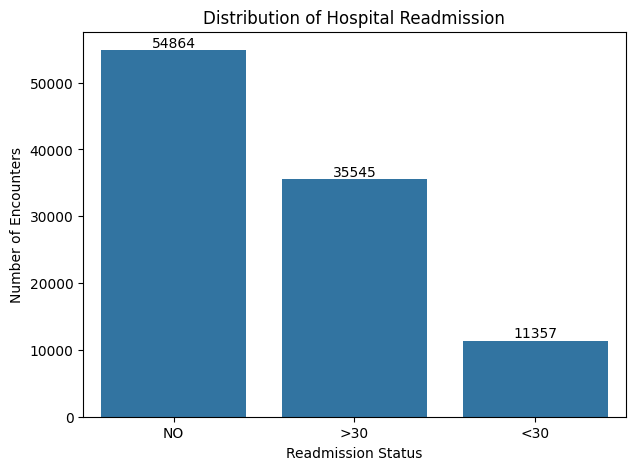

In [11]:
plt.figure(figsize=(7, 5))

ax = sns.countplot(data=df, x='readmitted')

for container in ax.containers:
    ax.bar_label(container, fmt='%d')

plt.title('Distribution of Hospital Readmission')
plt.xlabel('Readmission Status')
plt.ylabel('Number of Encounters')

plt.show()


- **Observation:** The <30 category contains considerably fewer records than the other two categories. This indicates a class imbalance that we must investigate.
- **53.92% of encounters have no readmission.**
- **34.93% are readmitted after 30 days.**
- **Only 11.16% are readmitted within 30 days.**

## Missing analysis 

In [12]:
missing_values = df.isnull().sum()

missing_values

encounter_id                    0
patient_nbr                     0
race                            0
gender                          0
age                             0
weight                          0
admission_type_id               0
discharge_disposition_id        0
admission_source_id             0
time_in_hospital                0
payer_code                      0
medical_specialty               0
num_lab_procedures              0
num_procedures                  0
num_medications                 0
number_outpatient               0
number_emergency                0
number_inpatient                0
diag_1                          0
diag_2                          0
diag_3                          0
number_diagnoses                0
max_glu_serum               96420
A1Cresult                   84748
metformin                       0
repaglinide                     0
nateglinide                     0
chlorpropamide                  0
glimepiride                     0
acetohexamide 

In [13]:
missing_percentage = (missing_values / len(df)) * 100

print(missing_percentage)

encounter_id                 0.000000
patient_nbr                  0.000000
race                         0.000000
gender                       0.000000
age                          0.000000
weight                       0.000000
admission_type_id            0.000000
discharge_disposition_id     0.000000
admission_source_id          0.000000
time_in_hospital             0.000000
payer_code                   0.000000
medical_specialty            0.000000
num_lab_procedures           0.000000
num_procedures               0.000000
num_medications              0.000000
number_outpatient            0.000000
number_emergency             0.000000
number_inpatient             0.000000
diag_1                       0.000000
diag_2                       0.000000
diag_3                       0.000000
number_diagnoses             0.000000
max_glu_serum               94.746772
A1Cresult                   83.277322
metformin                    0.000000
repaglinide                  0.000000
nateglinide 

In [14]:
missing_df = pd.DataFrame({
    'Missing_Values': missing_values,
    'Missing_Percentage': missing_percentage
})

missing_df = missing_df[
    missing_df['Missing_Values'] > 0
].sort_values(by='Missing_Percentage', ascending=False)

missing_df

,Missing_Values,Missing_Percentage
max_glu_serum,96420,94.746772
A1Cresult,84748,83.277322


In [15]:
question_mark_count = df.astype(str).eq('?').sum()

print(question_mark_count)

encounter_id                    0
patient_nbr                     0
race                         2273
gender                          0
age                             0
weight                      98569
admission_type_id               0
discharge_disposition_id        0
admission_source_id             0
time_in_hospital                0
payer_code                  40256
medical_specialty           49949
num_lab_procedures              0
num_procedures                  0
num_medications                 0
number_outpatient               0
number_emergency                0
number_inpatient                0
diag_1                         21
diag_2                        358
diag_3                       1423
number_diagnoses                0
max_glu_serum                   0
A1Cresult                       0
metformin                       0
repaglinide                     0
nateglinide                     0
chlorpropamide                  0
glimepiride                     0
acetohexamide 

In [16]:
question_mark_percentage = (question_mark_count / len(df)) * 100
print(question_mark_percentage)

encounter_id                 0.000000
patient_nbr                  0.000000
race                         2.233555
gender                       0.000000
age                          0.000000
weight                      96.858479
admission_type_id            0.000000
discharge_disposition_id     0.000000
admission_source_id          0.000000
time_in_hospital             0.000000
payer_code                  39.557416
medical_specialty           49.082208
num_lab_procedures           0.000000
num_procedures               0.000000
num_medications              0.000000
number_outpatient            0.000000
number_emergency             0.000000
number_inpatient             0.000000
diag_1                       0.020636
diag_2                       0.351787
diag_3                       1.398306
number_diagnoses             0.000000
max_glu_serum                0.000000
A1Cresult                    0.000000
metformin                    0.000000
repaglinide                  0.000000
nateglinide 

In [17]:
question_mark_df = pd.DataFrame({
    'Question_Mark_Count': question_mark_count,
    'Percentage': question_mark_percentage
})

question_mark_df = question_mark_df[
    question_mark_df['Question_Mark_Count'] > 0
].sort_values(by='Percentage', ascending=False)

question_mark_df

,Question_Mark_Count,Percentage
weight,98569,96.858479
medical_specialty,49949,49.082208
payer_code,40256,39.557416
race,2273,2.233555
diag_3,1423,1.398306
diag_2,358,0.351787
diag_1,21,0.020636


### Observation

From the missing value analysis, I observed that the dataset contains two forms of missing data:

1. **Actual null values**
2. Missing values represented by the **`?`** symbol

Among the columns with actual null values, **`max_glu_serum`** has the highest percentage of missing data (**94.75%**), followed by **`A1Cresult`** (**83.28%**).

For columns where missing values are represented by **`?`**, **`weight`** has the highest proportion of missing records (**96.86%**), followed by **`medical_specialty`** and **`payer_code`**.

These observations indicate that several features have a substantial amount of missing information and should be carefully evaluated before deciding on appropriate preprocessing or imputation techniques.

#### Check unique values

In [18]:
# Check unique values in each column
for col in df.columns:
    print(f"{col}: {df[col].nunique()} unique values")

encounter_id: 101766 unique values
patient_nbr: 71518 unique values
race: 6 unique values
gender: 3 unique values
age: 10 unique values
weight: 10 unique values
admission_type_id: 8 unique values
discharge_disposition_id: 26 unique values
admission_source_id: 17 unique values
time_in_hospital: 14 unique values
payer_code: 18 unique values
medical_specialty: 73 unique values
num_lab_procedures: 118 unique values
num_procedures: 7 unique values
num_medications: 75 unique values
number_outpatient: 39 unique values
number_emergency: 33 unique values
number_inpatient: 21 unique values
diag_1: 717 unique values
diag_2: 749 unique values
diag_3: 790 unique values
number_diagnoses: 16 unique values
max_glu_serum: 3 unique values
A1Cresult: 3 unique values
metformin: 4 unique values
repaglinide: 4 unique values
nateglinide: 4 unique values
chlorpropamide: 4 unique values
glimepiride: 4 unique values
acetohexamide: 2 unique values
glipizide: 4 unique values
glyburide: 4 unique values
tolbutamide

#### Inspect categorical values

In [19]:
categorical_columns = [
    'race',
    'gender',
    'weight',
    'payer_code',
    'medical_specialty',
    'max_glu_serum',
    'A1Cresult',
    'change',
    'diabetesMed'
]

for col in categorical_columns:
    print(f"\n--- {col} ---")
    print(df[col].value_counts(dropna=False))


--- race ---
race
Caucasian          76099
AfricanAmerican    19210
?                   2273
Hispanic            2037
Other               1506
Asian                641
Name: count, dtype: int64

--- gender ---
gender
Female             54708
Male               47055
Unknown/Invalid        3
Name: count, dtype: int64

--- weight ---
weight
?            98569
[75-100)      1336
[50-75)        897
[100-125)      625
[125-150)      145
[25-50)         97
[0-25)          48
[150-175)       35
[175-200)       11
>200             3
Name: count, dtype: int64

--- payer_code ---
payer_code
?     40256
MC    32439
HM     6274
SP     5007
BC     4655
MD     3532
CP     2533
UN     2448
CM     1937
OG     1033
PO      592
DM      549
CH      146
WC      135
OT       95
MP       79
SI       55
FR        1
Name: count, dtype: int64

--- medical_specialty ---
medical_specialty
?                         49949
InternalMedicine          14635
Emergency/Trauma           7565
Family/GeneralPractice     7

#### Inspect medication columns

In [20]:
medication_columns = [
    'metformin', 'repaglinide', 'nateglinide',
    'chlorpropamide', 'glimepiride', 'acetohexamide',
    'glipizide', 'glyburide', 'tolbutamide',
    'pioglitazone', 'rosiglitazone', 'acarbose',
    'miglitol', 'troglitazone', 'tolazamide',
    'insulin', 'glyburide-metformin',
    'glipizide-metformin', 'glimepiride-pioglitazone',
    'metformin-rosiglitazone', 'metformin-pioglitazone'
]

for col in medication_columns:
    print(f"\n--- {col} ---")
    print(df[col].value_counts(dropna=False))


--- metformin ---
metformin
No        81778
Steady    18346
Up         1067
Down        575
Name: count, dtype: int64

--- repaglinide ---
repaglinide
No        100227
Steady      1384
Up           110
Down          45
Name: count, dtype: int64

--- nateglinide ---
nateglinide
No        101063
Steady       668
Up            24
Down          11
Name: count, dtype: int64

--- chlorpropamide ---
chlorpropamide
No        101680
Steady        79
Up             6
Down           1
Name: count, dtype: int64

--- glimepiride ---
glimepiride
No        96575
Steady     4670
Up          327
Down        194
Name: count, dtype: int64

--- acetohexamide ---
acetohexamide
No        101765
Steady         1
Name: count, dtype: int64

--- glipizide ---
glipizide
No        89080
Steady    11356
Up          770
Down        560
Name: count, dtype: int64

--- glyburide ---
glyburide
No        91116
Steady     9274
Up          812
Down        564
Name: count, dtype: int64

--- tolbutamide ---
tolbutamide
No 

#### Inspect diagnosis columns

In [21]:
diagnosis_columns = ['diag_1', 'diag_2', 'diag_3']

for col in diagnosis_columns:
    print(f"\n--- {col} ---")
    print(df[col].value_counts().head(15))
    print("Unique values:", df[col].nunique())
    print("Question marks:", (df[col] == '?').sum())


--- diag_1 ---
diag_1
428      6862
414      6581
786      4016
410      3614
486      3508
427      2766
491      2275
715      2151
682      2042
434      2028
780      2019
996      1967
276      1889
38       1688
250.8    1680
Name: count, dtype: int64
Unique values: 717
Question marks: 21

--- diag_2 ---
diag_2
276       6752
428       6662
250       6071
427       5036
401       3736
496       3305
599       3288
403       2823
414       2650
411       2566
250.02    2074
707       1999
585       1871
584       1649
491       1545
Name: count, dtype: int64
Unique values: 749
Question marks: 358

--- diag_3 ---
diag_3
250       11555
401        8289
276        5175
428        4577
427        3955
414        3664
496        2605
403        2357
585        1992
272        1969
599        1941
?          1423
V45        1389
250.02     1369
707        1360
Name: count, dtype: int64
Unique values: 790
Question marks: 1423


#### Inspect numerical columns

In [22]:
numerical_columns = df.select_dtypes(include=['int64', 'float64']).columns

print("Numerical columns:")
print(list(numerical_columns))

print("\nStatistical Summary:")
display(df[numerical_columns].describe().T)

Numerical columns:
['encounter_id', 'patient_nbr', 'admission_type_id', 'discharge_disposition_id', 'admission_source_id', 'time_in_hospital', 'num_lab_procedures', 'num_procedures', 'num_medications', 'number_outpatient', 'number_emergency', 'number_inpatient', 'number_diagnoses']

Statistical Summary:


,count,mean,std,min,25%,50%,75%,max
encounter_id,101766.0,1.652016e+08,1.026403e+08,12522.0,84961194.0,152388987.0,2.302709e+08,443867222.0
patient_nbr,101766.0,5.433040e+07,3.869636e+07,135.0,23413221.0,45505143.0,8.754595e+07,189502619.0
admission_type_id,101766.0,2.024006e+00,1.445403e+00,1.0,1.0,1.0,3.000000e+00,8.0
discharge_disposition_id,101766.0,3.715642e+00,5.280166e+00,1.0,1.0,1.0,4.000000e+00,28.0
admission_source_id,101766.0,5.754437e+00,4.064081e+00,1.0,1.0,7.0,7.000000e+00,25.0
time_in_hospital,101766.0,4.395987e+00,2.985108e+00,1.0,2.0,4.0,6.000000e+00,14.0
num_lab_procedures,101766.0,4.309564e+01,1.967436e+01,1.0,31.0,44.0,5.700000e+01,132.0
num_procedures,101766.0,1.339730e+00,1.705807e+00,0.0,0.0,1.0,2.000000e+00,6.0
num_medications,101766.0,1.602184e+01,8.127566e+00,1.0,10.0,15.0,2.000000e+01,81.0
number_outpatient,101766.0,3.693572e-01,1.267265e+00,0.0,0.0,0.0,0.000000e+00,42.0


Important observations
- number_outpatient, number_emergency, and number_inpatient have minimum values of zero.
- Their maximum values are considerably higher than their typical values.
- num_medications ranges from 1 to 81.
- The numerical features have different scales.

In [23]:
print(ids_mapping.to_string(index=False))

       admission_type_id                                                                                               description
                       1                                                                                                 Emergency
                       2                                                                                                    Urgent
                       3                                                                                                  Elective
                       4                                                                                                   Newborn
                       5                                                                                             Not Available
                       6                                                                                                       NaN
                       7                                                           

In [24]:
id_columns = [
    'admission_type_id',
    'discharge_disposition_id',
    'admission_source_id'
]

for col in id_columns:
    print(f"\n--- {col} ---")
    print(df[col].value_counts().sort_index())


--- admission_type_id ---
admission_type_id
1    53990
2    18480
3    18869
4       10
5     4785
6     5291
7       21
8      320
Name: count, dtype: int64

--- discharge_disposition_id ---
discharge_disposition_id
1     60234
2      2128
3     13954
4       815
5      1184
6     12902
7       623
8       108
9        21
10        6
11     1642
12        3
13      399
14      372
15       63
16       11
17       14
18     3691
19        8
20        2
22     1993
23      412
24       48
25      989
27        5
28      139
Name: count, dtype: int64

--- admission_source_id ---
admission_source_id
1     29565
2      1104
3       187
4      3187
5       855
6      2264
7     57494
8        16
9       125
10        8
11        2
13        1
14        2
17     6781
20      161
22       12
25        2
Name: count, dtype: int64


- **Observation:** Emergency admissions are the most frequent, with 53,990 records. Newborn and Trauma Center categories have very few records.

**Important:** IDs 11, 13, and 14 represent discharge outcomes that require special consideration. We should investigate their relationship with the target before deciding whether to exclude them.

Also, ID 18 has 3,691 records but no description in the mapping file. We must preserve this information rather than invent a description.

- **Observation:** Emergency Room is the most common admission source, accounting for 57,494 records.

#### Investigate discharge disposition against readmission

In [25]:
discharge_readmission = pd.crosstab(
    df['discharge_disposition_id'],
    df['readmitted'],
    margins=True
)

discharge_readmission

readmitted,<30,>30,NO,All
discharge_disposition_id,,,,
1,5602,21517,33115,60234
2,342,668,1118,2128
3,2046,4916,6992,13954
4,104,278,433,815
5,247,350,587,1184
6,1638,5362,5902,12902
7,90,221,312,623
8,15,38,55,108
9,9,2,10,21


In [26]:
discharge_readmission_pct = pd.crosstab(
    df['discharge_disposition_id'],
    df['readmitted'],
    normalize='index'
) * 100

discharge_readmission_pct.round(2)

readmitted,<30,>30,NO
discharge_disposition_id,,,
1,9.30,35.72,54.98
2,16.07,31.39,52.54
3,14.66,35.23,50.11
4,12.76,34.11,53.13
5,20.86,29.56,49.58
6,12.70,41.56,45.74
7,14.45,35.47,50.08
8,13.89,35.19,50.93
9,42.86,9.52,47.62


##### Expired patients(11,19,20)
All 1,652 records in these three categories have NO as their readmission label.

This makes sense because a patient who has died cannot subsequently be readmitted.

##### Hospice patients(13,14)
Unlike the expired categories, hospice categories contain some readmission records.

Therefore, we should not automatically treat hospice patients as equivalent to expired patients.

In [27]:
# Discharge disposition IDs representing expired patients
expired_ids = [11, 19, 20]

# Create a separate dataset
eligible_df = df[
    ~df['discharge_disposition_id'].isin(expired_ids)
].copy()

print("Original dataset shape:", df.shape)
print("Eligible dataset shape:", eligible_df.shape)

print("\nRemoved records:")
print(len(df) - len(eligible_df))

print("\nReadmission distribution after exclusion:")
print(eligible_df['readmitted'].value_counts())

Original dataset shape: (101766, 50)
Eligible dataset shape: (100114, 50)

Removed records:
1652

Readmission distribution after exclusion:
readmitted
NO     53212
>30    35545
<30    11357
Name: count, dtype: int64


### Observation

During the analysis of the **`discharge_disposition_id`** feature, I identified **1,652 records** corresponding to expired patients (disposition IDs **11, 19, and 20**). Since these patients cannot be readmitted after discharge, they were removed from the dataset to ensure the target population accurately reflects patients who are eligible for future readmission.

After excluding these records, the dataset size was reduced to **100,114 encounters**.

I also observed that the target variable is imbalanced. Patients readmitted within **30 days (`<30`)** account for only **11.34%** of the eligible dataset, while the remaining records belong to the majority class. This class imbalance should be considered during model development and evaluation.

#### Investigate patient-level duplicates

In [28]:
# Number of unique patients
unique_patients = eligible_df['patient_nbr'].nunique()

In [29]:
# Number of encounters
total_encounters = len(eligible_df)


In [30]:
# Number of patients with multiple encounters
patient_counts = eligible_df['patient_nbr'].value_counts()

In [31]:
multiple_encounter_patients = (
    patient_counts[patient_counts > 1]
)


In [32]:
print("Total encounters:", total_encounters)
print("Unique patients:", unique_patients)


Total encounters: 100114
Unique patients: 70439


In [33]:
print("Patients with multiple encounters:",len(multiple_encounter_patients))


Patients with multiple encounters: 16483


In [34]:
print("Maximum encounters for one patient:",patient_counts.max())

Maximum encounters for one patient: 40


- We have 100,114 hospital encounters, not 100,114 different patients.
- 16,483 patients have multiple encounters.
- One patient has as many as 40 encounters.

**Important:** These are not duplicate rows. They are separate hospital encounters belonging to the same patient.

- We should use a patient-group-based split so that all encounters belonging to one patient stay in the same dataset.

In [35]:
patient_counts.describe()

count    70439.000000
mean         1.421287
std          1.088970
min          1.000000
25%          1.000000
50%          1.000000
75%          1.000000
max         40.000000
Name: count, dtype: float64

The dataset contains 100,114 encounters belonging to 70,439 unique patients. The average number of encounters per patient is approximately 1.42, while the median is 1. Some patients have multiple encounters, with a maximum of 40. Therefore, patient-level grouping must be considered during data splitting to prevent the same patient's records from appearing in both training and testing datasets.

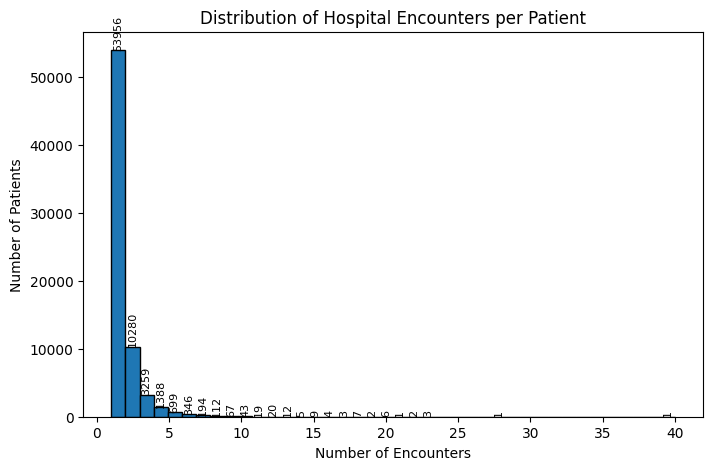

In [36]:
plt.figure(figsize=(8, 5))

counts, bins, patches = plt.hist(
    patient_counts,
    bins=40,
    edgecolor='black'
)

# Add labels on bars
for count, patch in zip(counts, patches):
    if count > 0:
        plt.text(
            patch.get_x() + patch.get_width() / 2,
            count,
            f'{int(count)}',
            ha='center',
            va='bottom',
            fontsize=8,
            rotation=90
        )

plt.title('Distribution of Hospital Encounters per Patient')
plt.xlabel('Number of Encounters')
plt.ylabel('Number of Patients')

plt.show()

From the graph, I can observe:
1. Most patients have only one hospital encounter.
2. The number of patients decreases as the number of encounters increases.
3. A small number of patients have multiple encounters.
4. A few patients have a very high number of encounters, with the maximum reaching 40.
This confirms that the dataset contains repeated encounters for some patients.

### Observation

The distribution of hospital encounters per patient is highly right-skewed. I observed that the majority of patients have only a single hospital encounter, while a relatively small number of patients have multiple encounters recorded in the dataset.

This indicates that several records may belong to the same patient. To prevent data leakage and ensure reliable model evaluation, patient-level grouping should be maintained when creating the train, validation, and test datasets so that encounters from the same patient do not appear across different data splits.

#### identify columns that contain only one unique value.

In [38]:
constant_columns = [
    col for col in eligible_df.columns
    if eligible_df[col].nunique() == 1
]

print("Constant columns:", constant_columns)

Constant columns: ['examide', 'citoglipton']


The constant-column analysis identified examide and citoglipton as features with only one unique value. Since these features do not provide any discriminatory information, they will be removed during data preparation.

#### Prepare the dataset for missing-value treatment

Pandas recognizes NaN as a missing value, but it treats ? as ordinary text. Converting these markers allows us to analyze and handle all missing values consistently.

In [40]:
# Create a working copy of the eligible dataset
prepared_df = eligible_df.copy()

In [41]:
# Convert '?' markers into actual missing values
prepared_df.replace('?', np.nan, inplace=True)


In [42]:
# Verify the replacement
print("Dataset shape:", prepared_df.shape)

Dataset shape: (100114, 50)


In [43]:
print("\nMissing values after replacement:")
print(prepared_df.isnull().sum().sort_values(ascending=False).head(10))


Missing values after replacement:
weight               96958
max_glu_serum        94890
A1Cresult            83238
medical_specialty    49129
payer_code           39591
race                  2239
diag_3                1421
diag_2                 358
diag_1                  21
patient_nbr              0
dtype: int64


**Important:** We should not automatically delete every column with many missing values. In particular, missing glucose and A1C results may indicate that the test was not performed, which could itself be useful information.

#### Understand the missing-value patterns

In [44]:
# Inspect values in columns with high missing percentages

columns_to_check = [
    'weight',
    'max_glu_serum',
    'A1Cresult'
]

for col in columns_to_check:
    print(f"\n--- {col} ---")
    print(prepared_df[col].value_counts(dropna=False))


--- weight ---
weight
NaN          96958
[75-100)      1320
[50-75)        881
[100-125)      622
[125-150)      143
[25-50)         94
[0-25)          48
[150-175)       34
[175-200)       11
>200             3
Name: count, dtype: int64

--- max_glu_serum ---
max_glu_serum
NaN     94890
Norm     2573
>200     1440
>300     1211
Name: count, dtype: int64

--- A1Cresult ---
A1Cresult
NaN     83238
>8       8151
Norm     4941
>7       3784
Name: count, dtype: int64


### Findings and Handling Strategy

- **`weight`** has **96.85% missing values** (96,958 records). Since only 3,156 records contain data and values are stored as weight ranges rather than exact measurements, this column will be **dropped**.

- **`max_glu_serum`** has **94.78% missing values** (94,890 records). As this feature represents categorical glucose test results (`Norm`, `>200`, `>300`), missing values will be replaced with **`Not_Measured`** to preserve information about whether the test was conducted.

- **`A1Cresult`** has **83.14% missing values** (83,238 records). Similar to `max_glu_serum`, missing values will be replaced with **`Not_Measured`** since the feature contains categorical test outcomes (`Norm`, `>7`, `>8`).

**Final Decision:** Drop `weight` and replace missing values in `max_glu_serum` and `A1Cresult` with **`Not_Measured`** instead of using mode or median imputation.

In [45]:
# Drop weight because it has approximately 97% missing values
prepared_df.drop(columns=['weight'], inplace=True)


In [46]:
# Preserve missing test results as a separate category
prepared_df['max_glu_serum'] = (
    prepared_df['max_glu_serum'].fillna('Not_Measured')
)

In [47]:
prepared_df['A1Cresult'] = (
    prepared_df['A1Cresult'].fillna('Not_Measured')
)

In [48]:
# Verify the changes
print("Dataset shape:", prepared_df.shape)


Dataset shape: (100114, 49)


In [49]:
print("\nMissing values:")
print(prepared_df[['max_glu_serum', 'A1Cresult']].isnull().sum())


Missing values:
max_glu_serum    0
A1Cresult        0
dtype: int64


In [50]:
print("\nMax glucose serum distribution:")
print(prepared_df['max_glu_serum'].value_counts())


Max glucose serum distribution:
max_glu_serum
Not_Measured    94890
Norm             2573
>200             1440
>300             1211
Name: count, dtype: int64


In [51]:
print("\nA1C result distribution:")
print(prepared_df['A1Cresult'].value_counts())


A1C result distribution:
A1Cresult
Not_Measured    83238
>8               8151
Norm             4941
>7               3784
Name: count, dtype: int64


What I have completed
- Removed weight because 96.85% of its values were missing.
- Replaced missing max_glu_serum values with Not_Measured.
- Replaced missing A1Cresult values with Not_Measured.
- Verified that both test-result columns now have zero missing values.

#### Handle the remaining categorical missing values

In [54]:
# Inspect remaining columns containing missing values

missing_summary = prepared_df.isnull().sum()
missing_summary = missing_summary[missing_summary > 0]

In [55]:
missing_percentage = (
    missing_summary / len(prepared_df) * 100
)

In [56]:
remaining_missing = pd.DataFrame({
    'Missing_Values': missing_summary,
    'Missing_Percentage': missing_percentage
}).sort_values(
    by='Missing_Percentage',
    ascending=False
)

print(remaining_missing)

                   Missing_Values  Missing_Percentage
medical_specialty           49129           49.073057
payer_code                  39591           39.545918
race                         2239            2.236450
diag_3                       1421            1.419382
diag_2                        358            0.357592
diag_1                         21            0.020976


In [57]:
# Columns with remaining missing categorical values
categorical_missing_cols = [
    'medical_specialty',
    'payer_code',
    'race',
    'diag_1',
    'diag_2',
    'diag_3'
]

In [58]:
# Replace missing values with Unknown
for col in categorical_missing_cols:
    prepared_df[col] = prepared_df[col].fillna('Unknown')


In [59]:
# Verify missing values
print("Remaining missing values:")
print(prepared_df.isnull().sum().sum())

print("\nDataset shape:", prepared_df.shape)

Remaining missing values:
0

Dataset shape: (100114, 49)


### Missing Value Handling

I replaced missing values in **`medical_specialty`** and **`payer_code`** with **`Unknown`** because these columns contain a high percentage of missing values. Using `Unknown` preserves the information that the value was unavailable without incorrectly assigning an existing category.

For **`race`**, I also used **`Unknown`** for missing values. Since only a small proportion of records were missing, this approach allowed all records to be retained while avoiding assumptions about a patient's demographic information.

For **`diag_1`**, **`diag_2`**, and **`diag_3`**, missing values were replaced with **`Unknown`** instead of the most frequent diagnosis code. Since these features represent medical diagnoses, imputing a diagnosis could introduce inaccurate clinical information and potentially bias the analysis.

**Final Decision:** Missing values in `medical_specialty`, `payer_code`, `race`, `diag_1`, `diag_2`, and `diag_3` were replaced with **`Unknown`** to preserve missingness information while avoiding misleading imputations.

In [61]:
# Remove columns identified as constant during EDA
constant_columns = ['examide', 'citoglipton']

prepared_df.drop(columns=constant_columns, inplace=True)

# Verify
print("Removed columns:", constant_columns)
print("Updated dataset shape:", prepared_df.shape)

print("\nRemaining constant columns:")
print([
    col for col in prepared_df.columns
    if prepared_df[col].nunique() == 1
])

Removed columns: ['examide', 'citoglipton']
Updated dataset shape: (100114, 47)

Remaining constant columns:
[]


## Outlier detection

In [63]:
numerical_columns = [
    'time_in_hospital',
    'num_lab_procedures',
    'num_procedures',
    'num_medications',
    'number_outpatient',
    'number_emergency',
    'number_inpatient',
    'number_diagnoses'
]

In [64]:
outlier_summary = []

for col in numerical_columns:

    Q1 = prepared_df[col].quantile(0.25)
    Q3 = prepared_df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = prepared_df[
        (prepared_df[col] < lower_bound) |
        (prepared_df[col] > upper_bound)
    ]

    outlier_summary.append({
        'Feature': col,
        'Lower_Bound': lower_bound,
        'Upper_Bound': upper_bound,
        'Outlier_Count': len(outliers),
        'Outlier_Percentage': round(
            len(outliers) / len(prepared_df) * 100, 2
        )
    })

outlier_df = pd.DataFrame(outlier_summary)

outlier_df

,Feature,Lower_Bound,Upper_Bound,Outlier_Count,Outlier_Percentage
0,time_in_hospital,-4.0,12.0,2186,2.18
1,num_lab_procedures,-8.0,96.0,122,0.12
2,num_procedures,-3.0,5.0,4811,4.81
3,num_medications,-5.0,35.0,2470,2.47
4,number_outpatient,0.0,0.0,16490,16.47
5,number_emergency,0.0,0.0,11189,11.18
6,number_inpatient,-1.5,2.5,6897,6.89
7,number_diagnoses,1.5,13.5,278,0.28


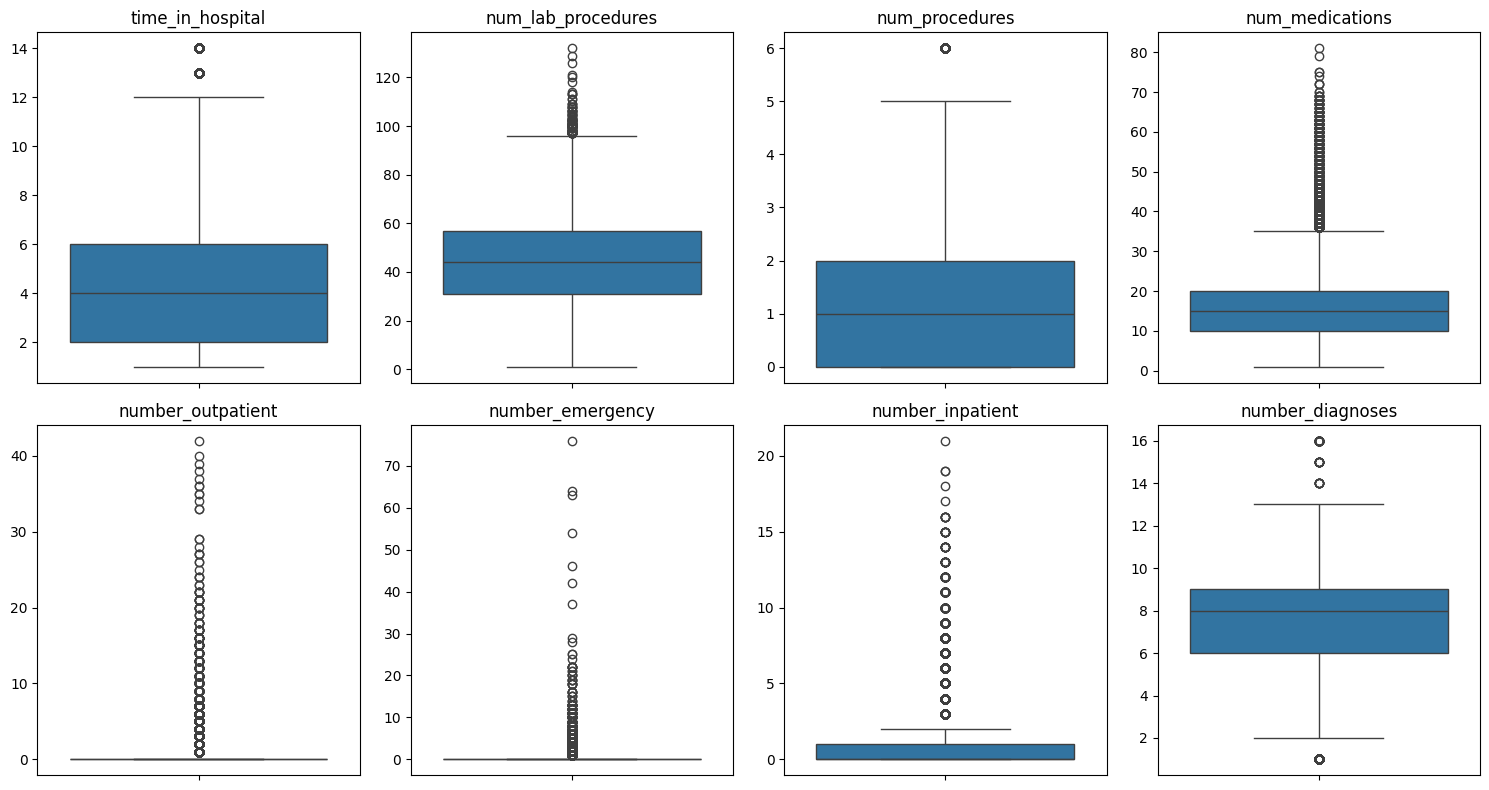

In [65]:
plt.figure(figsize=(15, 8))

for i, col in enumerate(numerical_columns, 1):
    plt.subplot(2, 4, i)
    sns.boxplot(y=prepared_df[col])
    plt.title(col)
    plt.ylabel('')

plt.tight_layout()
plt.show()

### Outlier Detection and Analysis

Outlier detection was performed using the Interquartile Range (IQR) method on eight numerical features.

The analysis identified varying proportions of potential outliers across the numerical features. The highest proportions were observed in `number_outpatient` (16.47%) and `number_emergency` (11.18%).

The boxplots revealed that previous hospital visit features contain many zero values and are highly right-skewed. For these features, the IQR can become zero, causing all positive observations to be flagged as outliers.

However, these observations may represent genuine patient medical histories rather than incorrect data. Similarly, higher hospitalization duration, laboratory procedures, medications and diagnoses may reflect differences in patient conditions.

**Decision:** No outlier records were removed or capped because the identified values may contain clinically meaningful information. All valid observations were retained for further analysis.

## Feature engineering

#### Age feature analysis
- We need to decide how to represent these age groups while preserving their natural order.

Age Group Distribution:
age
[0-10)        160
[10-20)       690
[20-30)      1650
[30-40)      3765
[40-50)      9626
[50-60)     17102
[60-70)     22185
[70-80)     25562
[80-90)     16706
[90-100)     2668
Name: count, dtype: int64


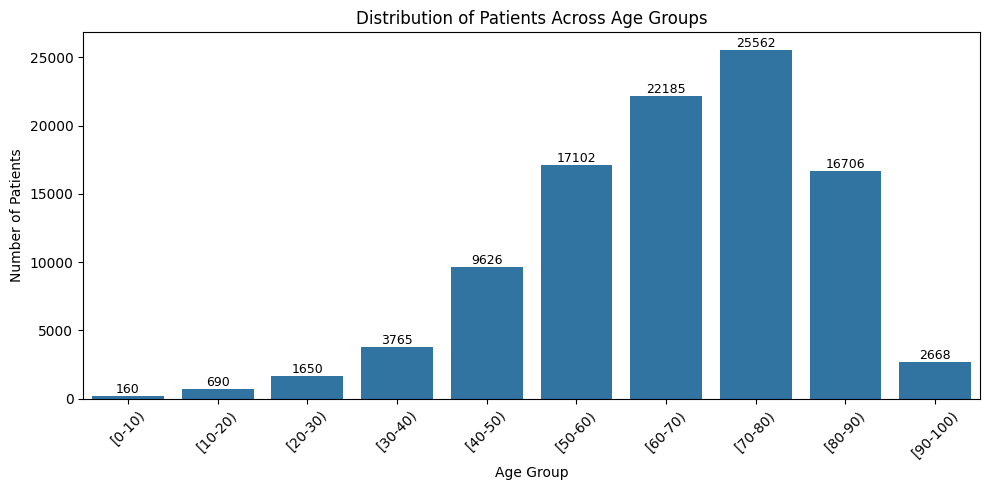

In [67]:
print("Age Group Distribution:")
print(prepared_df['age'].value_counts().sort_index())

plt.figure(figsize=(10, 5))

ax = sns.countplot(
    data=prepared_df,
    x='age',
    order=sorted(prepared_df['age'].unique())
)

# Add labels on bars
for p in ax.patches:
    ax.annotate(
        f'{int(p.get_height())}',
        (p.get_x() + p.get_width() / 2., p.get_height()),
        ha='center',
        va='bottom',
        fontsize=9
    )

plt.title('Distribution of Patients Across Age Groups')
plt.xlabel('Age Group')
plt.ylabel('Number of Patients')
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

Key observations
1. The largest age group is 70–80, containing 25,562 patient encounters.
2. The second-largest group is 60–70, containing 22,185 encounters.
3. Most hospital encounters belong to patients aged between 50 and 90.
4. Younger patients, particularly below 30, represent a comparatively small proportion.
Interpretation: The dataset predominantly represents older patients, which is relevant because age can be an important factor when studying diabetes-related hospital readmissions.

In [68]:
age_mapping = {
    '[0-10)': 5,
    '[10-20)': 15,
    '[20-30)': 25,
    '[30-40)': 35,
    '[40-50)': 45,
    '[50-60)': 55,
    '[60-70)': 65,
    '[70-80)': 75,
    '[80-90)': 85,
    '[90-100)': 95
}

prepared_df['age_midpoint'] = prepared_df['age'].map(age_mapping)

print(prepared_df[['age', 'age_midpoint']].drop_duplicates().sort_values('age_midpoint'))

print("\nMissing values in age_midpoint:",
      prepared_df['age_midpoint'].isnull().sum())

        age  age_midpoint
0    [0-10)             5
1   [10-20)            15
2   [20-30)            25
3   [30-40)            35
4   [40-50)            45
5   [50-60)            55
6   [60-70)            65
7   [70-80)            75
8   [80-90)            85
9  [90-100)            95

Missing values in age_midpoint: 0


The original age feature contains intervals rather than exact ages.

Converting intervals into midpoints:
- Makes age numerical.
- Preserves the natural order.
- Allows numerical scaling before MLP training.
- Avoids treating age groups as unrelated categories.
Important limitation: These are approximate ages, not patients' actual ages. We are assuming the midpoint represents each interval.


#### Create diagnosis categories

These columns contain hundreds of different diagnosis codes. Treating every code as an independent category can create a very large number of encoded features.

In [69]:
def categorize_diagnosis(code):

    if pd.isna(code) or str(code).strip() == 'Unknown':
        return 'Unknown'

    code = str(code).strip().upper()

    # V and E codes
    if code.startswith(('V', 'E')):
        return 'Other'

    try:
        code = int(float(code))
    except ValueError:
        return 'Unknown'

    if 390 <= code <= 459 or code == 785:
        return 'Circulatory'

    elif 460 <= code <= 519 or code == 786:
        return 'Respiratory'

    elif 520 <= code <= 579 or code == 787:
        return 'Digestive'

    elif code == 250:
        return 'Diabetes'

    elif 800 <= code <= 999:
        return 'Injury'

    elif 710 <= code <= 739:
        return 'Musculoskeletal'

    elif 580 <= code <= 629 or code == 788:
        return 'Genitourinary'

    elif 140 <= code <= 239:
        return 'Neoplasms'

    else:
        return 'Other'


# Create grouped diagnosis features
for col in ['diag_1', 'diag_2', 'diag_3']:

    prepared_df[col + '_group'] = prepared_df[col].apply(
        categorize_diagnosis
    )

In [70]:
diagnosis_group_columns = [
    'diag_1_group',
    'diag_2_group',
    'diag_3_group'
]

for col in diagnosis_group_columns:

    print(f"\n{col}")
    print(prepared_df[col].value_counts())


diag_1_group
diag_1_group
Circulatory        29881
Other              17887
Respiratory        14074
Digestive           9380
Diabetes            8693
Injury              6881
Genitourinary       5054
Musculoskeletal     4944
Neoplasms           3299
Unknown               21
Name: count, dtype: int64

diag_2_group
diag_2_group
Circulatory        31370
Other              26207
Diabetes           12722
Respiratory        10506
Genitourinary       8233
Digestive           4114
Neoplasms           2452
Injury              2390
Musculoskeletal     1762
Unknown              358
Name: count, dtype: int64

diag_3_group
diag_3_group
Circulatory        29789
Other              28796
Diabetes           17027
Respiratory         7096
Genitourinary       6519
Digestive           3885
Injury              1905
Musculoskeletal     1903
Neoplasms           1773
Unknown             1421
Name: count, dtype: int64


### Diagnosis Feature Engineering

The three diagnosis features (`diag_1`, `diag_2`, and `diag_3`) were categorized using ICD-9 code ranges into broader medical groups.

The analysis showed that circulatory diseases were the most frequent primary diagnosis category, with 29,881 encounters. Diabetes appeared more frequently in secondary and additional diagnoses, with 12,722 and 17,027 encounters respectively.

The Other category contained diagnosis codes that did not belong to the selected medical groups. Missing diagnosis information was retained as a separate Unknown category.

**Decision:** Three new grouped features (`diag_1_group`, `diag_2_group`, and `diag_3_group`) were created while preserving the original diagnosis columns for further evaluation.

In [71]:
for col in diagnosis_group_columns:

    print(f"\nReadmission distribution by {col}:")

    result = pd.crosstab(
        prepared_df[col],
        prepared_df['readmitted'],
        normalize='index'
    ) * 100

    print(result.round(2))


Readmission distribution by diag_1_group:
readmitted         <30    >30     NO
diag_1_group                        
Circulatory      11.66  36.27  52.06
Diabetes         13.08  38.17  48.75
Digestive        10.82  35.86  53.32
Genitourinary    10.98  33.95  55.07
Injury           12.41  32.51  55.08
Musculoskeletal   9.53  29.75  60.72
Neoplasms        10.49  24.25  65.26
Other            11.66  35.02  53.32
Respiratory       9.97  39.31  50.72
Unknown          23.81  19.05  57.14

Readmission distribution by diag_2_group:
readmitted         <30    >30     NO
diag_2_group                        
Circulatory      11.28  37.09  51.63
Diabetes         10.64  32.99  56.37
Digestive        11.64  33.91  54.45
Genitourinary    11.96  36.77  51.27
Injury           11.63  28.24  60.13
Musculoskeletal  10.05  33.77  56.19
Neoplasms        15.50  29.89  54.61
Other            11.41  34.92  53.67
Respiratory      10.91  38.67  50.42
Unknown           8.10  20.67  71.23

Readmission distribution 

### Relationship Between Diagnosis Categories and Readmission

The relationship between the three grouped diagnosis features and hospital readmission was investigated using row-wise percentage distributions.

The primary diagnosis analysis showed that Diabetes had the highest 30-day readmission percentage (13.08%) among the major diagnosis categories.

For secondary diagnoses, Neoplasms recorded the highest percentage (15.50%). Similarly, Neoplasms (14.89%) and Genitourinary conditions (13.79%) showed relatively higher percentages among additional diagnoses.

These observations indicate that different diagnosis categories have varying associations with hospital readmission. However, these are descriptive relationships and do not establish causation.

**Conclusion:** The three grouped diagnosis features will be retained for further evaluation because they may provide useful information for predicting 30-day hospital readmission.

In [72]:
prepared_df['total_previous_visits'] = (
    prepared_df['number_outpatient'] +
    prepared_df['number_emergency'] +
    prepared_df['number_inpatient']
)

print(prepared_df['total_previous_visits'].describe())

count    100114.000000
mean          1.200591
std           2.292775
min           0.000000
25%           0.000000
50%           0.000000
75%           2.000000
max          80.000000
Name: total_previous_visits, dtype: float64


Important observations
1. At least half of the patients had zero previous visits across the three categories.
2. 75% of encounters had two or fewer previous visits.
3. The maximum is 80, indicating a small number of patients had very frequent hospital utilization.
4. The mean (1.20) is greater than the median (0), suggesting a strongly right-skewed distribution.

In [73]:
visit_bins = [-1, 0, 1, 2, 3, float('inf')]

visit_labels = [
    '0 visits',
    '1 visit',
    '2 visits',
    '3 visits',
    '4+ visits'
]

prepared_df['previous_visits_group'] = pd.cut(
    prepared_df['total_previous_visits'],
    bins=visit_bins,
    labels=visit_labels
)

visit_readmission = pd.crosstab(
    prepared_df['previous_visits_group'],
    prepared_df['readmitted'],
    normalize='index'
) * 100

print(visit_readmission.round(2))

readmitted               <30    >30     NO
previous_visits_group                     
0 visits                8.30  28.43  63.28
1 visit                11.76  39.76  48.48
2 visits               14.92  44.30  40.78
3 visits               15.62  47.81  36.57
4+ visits              21.45  50.56  27.99


In [74]:
print(
    prepared_df['previous_visits_group']
    .value_counts()
    .sort_index()
)

previous_visits_group
0 visits     55018
1 visit      19609
2 visits      9860
3 visits      5773
4+ visits     9854
Name: count, dtype: int64


### Previous Hospital Utilization Feature Engineering

A new feature, `total_previous_visits`, was created by combining the number of previous outpatient, emergency and inpatient visits.

The analysis showed that the 30-day readmission rate increased with previous hospital utilization. Encounters with zero previous visits had an 8.30% readmission rate, whereas encounters with four or more previous visits had a 21.45% readmission rate.

Additionally, the proportion of encounters without readmission decreased from 63.28% to 27.99% across these groups.

**Decision:** The engineered feature `total_previous_visits` will be retained as a candidate predictive feature. Its contribution will be compared with the original three utilization features during model experimentation.

## Create medication change features

In [75]:
medication_columns = [
    'metformin', 'repaglinide', 'nateglinide',
    'chlorpropamide', 'glimepiride', 'acetohexamide',
    'glipizide', 'glyburide', 'tolbutamide',
    'pioglitazone', 'rosiglitazone', 'acarbose',
    'miglitol', 'troglitazone', 'tolazamide',
    'insulin', 'glyburide-metformin',
    'glipizide-metformin', 'glimepiride-pioglitazone',
    'metformin-rosiglitazone', 'metformin-pioglitazone'
]

# Count medications prescribed
prepared_df['total_medications_prescribed'] = (
    prepared_df[medication_columns] != 'No'
).sum(axis=1)

# Count medications with dosage changes
prepared_df['medications_changed'] = (
    prepared_df[medication_columns]
    .isin(['Up', 'Down'])
).sum(axis=1)

print(prepared_df[
    ['total_medications_prescribed', 'medications_changed']
].describe())

       total_medications_prescribed  medications_changed
count                 100114.000000        100114.000000
mean                       1.185568             0.287542
std                        0.921621             0.487859
min                        0.000000             0.000000
25%                        1.000000             0.000000
50%                        1.000000             0.000000
75%                        2.000000             1.000000
max                        6.000000             4.000000


In [76]:
print(
    pd.crosstab(
        prepared_df['medications_changed'],
        prepared_df['readmitted'],
        normalize='index'
    ).mul(100).round(2)
)

readmitted             <30    >30     NO
medications_changed                     
0                    10.62  34.31  55.07
1                    13.33  38.81  47.86
2                    12.16  36.85  50.99
3                    14.95  34.58  50.47
4                     0.00  40.00  60.00


In [77]:
print(
    prepared_df['medications_changed'].value_counts().sort_index()
)

medications_changed
0    72864
1    25830
2     1308
3      107
4        5
Name: count, dtype: int64


### Observation: Medication Changes

The `medications_changed` feature represents the number of diabetes medications whose dosage was increased or decreased during hospitalization.

Most encounters (72.78%) had no medication changes, while approximately 25.80% had one medication change. Only a small number of encounters had multiple medication changes.

The 30-day readmission percentage was 10.62% for encounters without medication changes and 13.33% for encounters with one medication change. This suggests a possible association between medication adjustments and readmission.

However, the relationship is not consistently increasing, and groups with multiple medication changes have very few observations. Therefore, this feature is retained as a candidate for further evaluation rather than considered a proven predictor.

In [78]:
pd.crosstab(
    prepared_df['total_medications_prescribed'],
    prepared_df['readmitted'],
    normalize='index'
).mul(100).round(2)

readmitted,<30,>30,NO
total_medications_prescribed,,,
0,9.83,31.64,58.53
1,12.53,37.01,50.46
2,10.80,36.21,52.99
3,10.50,36.06,53.44
4,10.26,34.57,55.17
5,0.00,32.76,67.24
6,40.00,40.00,20.00


In [79]:
prepared_df['total_medications_prescribed'].value_counts().sort_index()

total_medications_prescribed
0    22842
1    46433
2    21714
3     7737
4     1325
5       58
6        5
Name: count, dtype: int64

### Observation: Total Diabetes Medications Prescribed

The `total_medications_prescribed` feature represents the number of diabetes medications prescribed during hospitalization.

Most encounters involved one medication (46,433), followed by two medications (21,714). The 30-day readmission percentage was 9.83% for encounters with no diabetes medications and 12.53% for encounters with one medication.

However, the readmission percentages do not follow a consistent trend as the number of medications increases. Categories with five and six medications contain very few observations and should not be interpreted independently.

Therefore, this feature is retained as a candidate for further evaluation, but its additional predictive value must be assessed against existing medication-related features.

In [85]:
print("Change distribution:")
print(prepared_df['change'].value_counts())


Change distribution:
change
No    53671
Ch    46443
Name: count, dtype: int64


In [83]:
print("\nDiabetesMed distribution:")
print(prepared_df['diabetesMed'].value_counts())


DiabetesMed distribution:
diabetesMed
Yes    77272
No     22842
Name: count, dtype: int64


In [86]:
print("Readmission by medication change:")
print(
    pd.crosstab(
        prepared_df['change'],
        prepared_df['readmitted'],
        normalize='index'
    ).mul(100).round(2)
)

print("\nReadmission by diabetes medication prescription:")
print(
    pd.crosstab(
        prepared_df['diabetesMed'],
        prepared_df['readmitted'],
        normalize='index'
    ).mul(100).round(2)
)

Readmission by medication change:
readmitted    <30    >30     NO
change                         
Ch          11.97  37.19  50.84
No          10.80  34.05  55.15

Readmission by diabetes medication prescription:
readmitted     <30    >30     NO
diabetesMed                     
No            9.83  31.64  58.53
Yes          11.79  36.65  51.56


### Observation: Existing Medication Features

The `change` feature indicates whether the diabetes medication regimen was changed during hospitalization. Encounters with a medication change had an 11.97% 30-day readmission rate, compared with 10.80% for encounters without a change.

The `diabetesMed` feature indicates whether diabetes medication was prescribed. Encounters with diabetes medication prescriptions had an 11.79% 30-day readmission rate, compared with 9.83% for encounters without such prescriptions.

Both features show a possible association with 30-day readmission. Therefore, they are retained as candidate model features for further evaluation.

In [87]:
admission_columns = [
    'admission_type_id',
    'admission_source_id',
    'discharge_disposition_id'
]

for col in admission_columns:
    print(f"\n{col} distribution:")
    print(prepared_df[col].value_counts().sort_index())


admission_type_id distribution:
admission_type_id
1    52884
2    18226
3    18739
4       10
5     4690
6     5227
7       18
8      320
Name: count, dtype: int64

admission_source_id distribution:
admission_source_id
1     29322
2      1083
3       185
4      3132
5       814
6      2244
7     56363
8        15
9       125
10        8
11        2
13        1
14        2
17     6645
20      159
22       12
25        2
Name: count, dtype: int64

discharge_disposition_id distribution:
discharge_disposition_id
1     60234
2      2128
3     13954
4       815
5      1184
6     12902
7       623
8       108
9        21
10        6
12        3
13      399
14      372
15       63
16       11
17       14
18     3691
22     1993
23      412
24       48
25      989
27        5
28      139
Name: count, dtype: int64


* These columns contain categorical IDs, not numerical measurements.

* For example, admission type ID 8 is not greater than admission type ID 3 in any meaningful clinical sense.

In [88]:
for col in admission_columns:
    print(f"\nReadmission distribution by {col}:")
    print(
        pd.crosstab(
            prepared_df[col],
            prepared_df['readmitted'],
            normalize='index'
        ).mul(100).round(2)
    )


Readmission distribution by admission_type_id:
readmitted           <30    >30      NO
admission_type_id                      
1                  11.76  36.51   51.72
2                  11.34  35.40   53.26
3                  10.46  30.66   58.87
4                  10.00  20.00   70.00
5                  10.55  36.70   52.75
6                  11.21  42.68   46.11
7                   0.00   0.00  100.00
8                   8.44  26.25   65.31

Readmission distribution by admission_source_id:
readmitted             <30    >30      NO
admission_source_id                      
1                    10.67  32.88   56.45
2                    10.25  28.62   61.13
3                    15.68  31.35   52.97
4                     9.87  21.46   68.68
5                    12.41  28.99   58.60
6                     9.45  17.74   72.82
7                    11.92  38.44   49.64
8                    13.33  26.67   60.00
9                    10.40  12.80   76.80
10                    0.00  25.00   75.0

### Observation: Admission and Discharge Features

The admission-related features show different relationships with readmission.

The `admission_type_id` categories have relatively similar 30-day readmission percentages among the common categories.

The `admission_source_id` feature shows variation across admission sources, although several categories contain very few encounters.

The `discharge_disposition_id` feature shows more noticeable differences. For example, ID 1 has a 30-day readmission percentage of 9.30%, while IDs 2, 3 and 5 have percentages of 16.07%, 14.66% and 20.86%, respectively.

Some categories have very small sample sizes, so their readmission percentages should be interpreted cautiously.

These three features are retained as candidates for further evaluation. Category meanings and appropriate grouping will be investigated before encoding.

In [89]:
# 1. Admission type mapping
admission_type_map = {
    1: 'Emergency',
    2: 'Urgent',
    3: 'Elective',
    4: 'Newborn',
    5: 'Not Available',
    6: 'Not Specified',
    7: 'Trauma Center',
    8: 'Not Mapped'
}

# 2. Admission source mapping
admission_source_map = {
    1: 'Physician Referral',
    2: 'Clinic Referral',
    3: 'HMO Referral',
    4: 'Transfer from Hospital',
    5: 'Transfer from Skilled Nursing Facility',
    6: 'Transfer from Healthcare Facility',
    7: 'Emergency Room',
    8: 'Court or Law Enforcement',
    9: 'Not Available',
    10: 'Transfer from Critical Access Hospital',
    11: 'Normal Delivery',
    13: 'Sick Baby',
    14: 'Extramural Birth',
    17: 'Not Specified',
    20: 'Not Mapped',
    22: 'Transfer from Hospital Inpatient',
    25: 'Transfer from Ambulatory Surgery Center'
}

# 3. Discharge disposition mapping
discharge_map = {
    1: 'Home',
    2: 'Another Short-Term Hospital',
    3: 'Skilled Nursing Facility',
    4: 'Intermediate Care Facility',
    5: 'Other Inpatient Institution',
    6: 'Home with Home Health',
    7: 'Left Against Medical Advice',
    8: 'Home with Home IV Provider',
    9: 'Inpatient in Same Hospital',
    10: 'Neonate to Another Hospital',
    12: 'Still Patient',
    13: 'Hospice at Home',
    14: 'Hospice in Medical Facility',
    15: 'Medicare-Approved Swing Bed',
    16: 'Another Institution within Same Hospital',
    17: 'Outpatient Services within Same Hospital',
    18: 'Not Specified',
    22: 'Rehabilitation Facility',
    23: 'Long-Term Care Hospital',
    24: 'Medicaid-Certified Nursing Facility',
    25: 'Not Mapped',
    27: 'Federal Healthcare Facility',
    28: 'Psychiatric Hospital'
}

# Create descriptive columns
prepared_df['admission_type'] = prepared_df['admission_type_id'].map(admission_type_map)

prepared_df['admission_source'] = prepared_df['admission_source_id'].map(admission_source_map)

prepared_df['discharge_destination'] = prepared_df['discharge_disposition_id'].map(discharge_map)

In [90]:
mapping_columns = [
    'admission_type',
    'admission_source',
    'discharge_destination'
]

for col in mapping_columns:
    print(f"\n{col} distribution:")
    print(prepared_df[col].value_counts(dropna=False))


admission_type distribution:
admission_type
Emergency        52884
Elective         18739
Urgent           18226
Not Specified     5227
Not Available     4690
Not Mapped         320
Trauma Center       18
Newborn             10
Name: count, dtype: int64

admission_source distribution:
admission_source
Emergency Room                             56363
Physician Referral                         29322
Not Specified                               6645
Transfer from Hospital                      3132
Transfer from Healthcare Facility           2244
Clinic Referral                             1083
Transfer from Skilled Nursing Facility       814
HMO Referral                                 185
Not Mapped                                   159
Not Available                                125
Court or Law Enforcement                      15
Transfer from Hospital Inpatient              12
Transfer from Critical Access Hospital         8
Extramural Birth                               2
Normal Del

In [91]:
discharge_map[16] = 'Outpatient Services at Another Institution'
discharge_map[17] = 'Outpatient Services at Same Institution'

prepared_df['discharge_destination'] = (
    prepared_df['discharge_disposition_id'].map(discharge_map)
)

In [92]:
print(
    prepared_df['discharge_destination'].value_counts()
    .loc[
        [
            'Outpatient Services at Another Institution',
            'Outpatient Services at Same Institution'
        ]
    ]
)

discharge_destination
Outpatient Services at Another Institution    11
Outpatient Services at Same Institution       14
Name: count, dtype: int64


### Create the grouped columns

In [93]:
# Admission type grouping
admission_type_group_map = {
    'Emergency': 'Emergency',
    'Urgent': 'Urgent',
    'Elective': 'Elective',
    'Newborn': 'Other',
    'Trauma Center': 'Other',
    'Not Available': 'Unknown / Unavailable',
    'Not Specified': 'Unknown / Unavailable',
    'Not Mapped': 'Unknown / Unavailable'
}

# Admission source grouping
admission_source_group_map = {
    'Emergency Room': 'Emergency Room',
    'Physician Referral': 'Physician / Clinic Referral',
    'Clinic Referral': 'Physician / Clinic Referral',
    'HMO Referral': 'Physician / Clinic Referral',
    'Transfer from Hospital': 'Hospital Transfer',
    'Transfer from Hospital Inpatient': 'Hospital Transfer',
    'Transfer from Healthcare Facility': 'Other Healthcare Transfer',
    'Transfer from Skilled Nursing Facility': 'Other Healthcare Transfer',
    'Transfer from Critical Access Hospital': 'Other Healthcare Transfer',
    'Court or Law Enforcement': 'Other Sources',
    'Normal Delivery': 'Other Sources',
    'Sick Baby': 'Other Sources',
    'Extramural Birth': 'Other Sources',
    'Transfer from Ambulatory Surgery Center': 'Other Sources',
    'Not Available': 'Unknown / Unavailable',
    'Not Specified': 'Unknown / Unavailable',
    'Not Mapped': 'Unknown / Unavailable'
}

# Discharge destination grouping
discharge_group_map = {
    'Home': 'Home',
    'Home with Home Health': 'Home',
    'Home with Home IV Provider': 'Home',

    'Skilled Nursing Facility': 'Skilled Nursing / Intermediate Care',
    'Intermediate Care Facility': 'Skilled Nursing / Intermediate Care',
    'Medicaid-Certified Nursing Facility': 'Skilled Nursing / Intermediate Care',

    'Another Short-Term Hospital': 'Hospital / Inpatient Transfer',
    'Other Inpatient Institution': 'Hospital / Inpatient Transfer',
    'Inpatient in Same Hospital': 'Hospital / Inpatient Transfer',
    'Neonate to Another Hospital': 'Hospital / Inpatient Transfer',

    'Rehabilitation Facility': 'Rehabilitation / Long-Term Care',
    'Long-Term Care Hospital': 'Rehabilitation / Long-Term Care',
    'Medicare-Approved Swing Bed': 'Rehabilitation / Long-Term Care',

    'Hospice at Home': 'Hospice',
    'Hospice in Medical Facility': 'Hospice',

    'Psychiatric Hospital': 'Psychiatric / Federal Facility',
    'Federal Healthcare Facility': 'Psychiatric / Federal Facility',

    'Left Against Medical Advice': 'Left Against Medical Advice',

    'Outpatient Services at Another Institution': 'Other / Special',
    'Outpatient Services at Same Institution': 'Other / Special',
    'Still Patient': 'Other / Special',

    'Not Specified': 'Unknown / Unavailable',
    'Not Mapped': 'Unknown / Unavailable'
}

# Create grouped features
prepared_df['admission_type_group'] = (
    prepared_df['admission_type'].map(admission_type_group_map)
)

prepared_df['admission_source_group'] = (
    prepared_df['admission_source'].map(admission_source_group_map)
)

prepared_df['discharge_group'] = (
    prepared_df['discharge_destination'].map(discharge_group_map)
)

In [94]:
group_columns = [
    'admission_type_group',
    'admission_source_group',
    'discharge_group'
]

for col in group_columns:
    print(f"\n{col}:")
    print(prepared_df[col].value_counts(dropna=False))


admission_type_group:
admission_type_group
Emergency                52884
Elective                 18739
Urgent                   18226
Unknown / Unavailable    10237
Other                       28
Name: count, dtype: int64

admission_source_group:
admission_source_group
Emergency Room                 56363
Physician / Clinic Referral    30590
Unknown / Unavailable           6929
Hospital Transfer               3144
Other Healthcare Transfer       3066
Other Sources                     22
Name: count, dtype: int64

discharge_group:
discharge_group
Home                                   73244
Skilled Nursing / Intermediate Care    14817
Unknown / Unavailable                   4680
Hospital / Inpatient Transfer           3339
Rehabilitation / Long-Term Care         2468
Hospice                                  771
Left Against Medical Advice              623
Psychiatric / Federal Facility           144
Other / Special                           28
Name: count, dtype: int64


In [95]:
for col in group_columns:
    print(f"\nReadmission distribution by {col}:")
    print(
        pd.crosstab(
            prepared_df[col],
            prepared_df['readmitted'],
            normalize='index'
        ).mul(100).round(2)
    )


Readmission distribution by admission_type_group:
readmitted               <30    >30     NO
admission_type_group                      
Elective               10.46  30.66  58.87
Emergency              11.76  36.51  51.72
Other                   3.57   7.14  89.29
Unknown / Unavailable  10.82  39.43  49.75
Urgent                 11.34  35.40  53.26

Readmission distribution by admission_source_group:
readmitted                     <30    >30     NO
admission_source_group                          
Emergency Room               11.92  38.44  49.64
Hospital Transfer             9.89  21.47  68.64
Other Healthcare Transfer    10.21  20.74  69.05
Other Sources                 9.09  18.18  72.73
Physician / Clinic Referral  10.69  32.72  56.59
Unknown / Unavailable        10.69  36.87  52.43

Readmission distribution by discharge_group:
readmitted                             <30    >30     NO
discharge_group                                         
Home                                  9.91 

Interpretation:
- Emergency and urgent admissions have slightly higher readmission percentages than elective admissions.
- The Other category contains only 28 encounters, so its 3.57% rate is not reliable.
- Emergency Room admissions have the highest rate among the major groups.
- Hospital and healthcare transfers have lower percentages.
- Other Sources has only 22 encounters, so its rate should not be interpreted confidently.

- Home discharge has a relatively low 30-day readmission percentage.
- Rehabilitation and long-term care have a higher percentage.

- Hospital/inpatient transfers also show a higher percentage.

- Psychiatric/federal facility has the highest percentage, but it contains only 144 encounters.

- Hospice has a low percentage, but this should not be interpreted as evidence of better clinical outcomes. The clinical circumstances and competing outcomes differ substantially.

In [96]:
print("Total unique medical specialties:")
print(prepared_df['medical_specialty'].nunique())

print("\nMedical specialty distribution:")
print(prepared_df['medical_specialty'].value_counts())

Total unique medical specialties:
73

Medical specialty distribution:
medical_specialty
Unknown                   49129
InternalMedicine          14328
Emergency/Trauma           7449
Family/GeneralPractice     7302
Cardiology                 5296
                          ...  
Proctology                    1
Speech                        1
SportsMedicine                1
Perinatology                  1
Neurophysiology               1
Name: count, Length: 73, dtype: int64


In [97]:
(prepared_df['medical_specialty'].value_counts(normalize=True) * 100).round(2)

medical_specialty
Unknown                   49.07
InternalMedicine          14.31
Emergency/Trauma           7.44
Family/GeneralPractice     7.29
Cardiology                 5.29
                          ...  
Proctology                 0.00
Speech                     0.00
SportsMedicine             0.00
Perinatology               0.00
Neurophysiology            0.00
Name: proportion, Length: 73, dtype: float64

In [98]:
specialty_counts = (
    prepared_df['medical_specialty']
    .value_counts()
)

print(specialty_counts.to_string())

medical_specialty
Unknown                                 49129
InternalMedicine                        14328
Emergency/Trauma                         7449
Family/GeneralPractice                   7302
Cardiology                               5296
Surgery-General                          3068
Nephrology                               1544
Orthopedics                              1394
Orthopedics-Reconstructive               1231
Radiologist                              1129
Pulmonology                               856
Psychiatry                                853
Urology                                   684
ObstetricsandGynecology                   669
Surgery-Cardiovascular/Thoracic           642
Gastroenterology                          550
Surgery-Vascular                          527
Surgery-Neuro                             462
PhysicalMedicineandRehabilitation         391
Oncology                                  327
Pediatrics                                253
Neurology       

In [99]:
print(
    "Specialties with fewer than 100 encounters:",
    (specialty_counts < 100).sum()
)

print(
    "\nSpecialties with 100 or more encounters:",
    (specialty_counts >= 100).sum()
)

Specialties with fewer than 100 encounters: 44

Specialties with 100 or more encounters: 29


- Total specialties: 73
- Specialties with 100 or more encounters: 29
- Specialties with fewer than 100 encounters: 44
- Unknown specialty: 49,129 encounters (49.07%)
This means almost half of our dataset does not identify the medical specialty.

The 44 rare specialties should be handled carefully because their readmission percentages may be unstable.

In [100]:
specialty_analysis = (
    prepared_df.groupby('medical_specialty')
    .agg(
        total_encounters=('readmitted', 'size'),
        readmitted_within_30_days=(
            'readmitted',
            lambda x: (x == '<30').sum()
        )
    )
)

specialty_analysis['readmission_rate'] = (
    specialty_analysis['readmitted_within_30_days']
    / specialty_analysis['total_encounters'] * 100
).round(2)

specialty_analysis = specialty_analysis.sort_values(
    'total_encounters',
    ascending=False
)

print(specialty_analysis.to_string())

                                      total_encounters  readmitted_within_30_days  readmission_rate
medical_specialty                                                                                  
Unknown                                          49129                       5781             11.77
InternalMedicine                                 14328                       1646             11.49
Emergency/Trauma                                  7449                        846             11.36
Family/GeneralPractice                            7302                        883             12.09
Cardiology                                        5296                        425              8.02
Surgery-General                                   3068                        342             11.15
Nephrology                                        1544                        248             16.06
Orthopedics                                       1394                        151             10.83


In [101]:
# Identify specialties with at least 100 encounters
specialty_counts = prepared_df['medical_specialty'].value_counts()

common_specialties = specialty_counts[
    specialty_counts >= 100
].index

# Create a grouped specialty feature
prepared_df['medical_specialty_group'] = (
    prepared_df['medical_specialty'].apply(
        lambda x: x if x == 'Unknown' or x in common_specialties
        else 'Other'
    )
)

# Check the resulting distribution
print("Number of original categories:",
      prepared_df['medical_specialty'].nunique())

print("Number of grouped categories:",
      prepared_df['medical_specialty_group'].nunique())

print("\nGrouped specialty distribution:")
print(prepared_df['medical_specialty_group'].value_counts())

Number of original categories: 73
Number of grouped categories: 30

Grouped specialty distribution:
medical_specialty_group
Unknown                              49129
InternalMedicine                     14328
Emergency/Trauma                      7449
Family/GeneralPractice                7302
Cardiology                            5296
Surgery-General                       3068
Nephrology                            1544
Orthopedics                           1394
Orthopedics-Reconstructive            1231
Radiologist                           1129
Other                                  916
Pulmonology                            856
Psychiatry                             853
Urology                                684
ObstetricsandGynecology                669
Surgery-Cardiovascular/Thoracic        642
Gastroenterology                       550
Surgery-Vascular                       527
Surgery-Neuro                          462
PhysicalMedicineandRehabilitation      391
Oncology        

In [102]:
print("Number of unique payer codes:",
      prepared_df['payer_code'].nunique())

print("\nPayer code distribution:")
print(prepared_df['payer_code'].value_counts())

Number of unique payer codes: 18

Payer code distribution:
payer_code
Unknown    39591
MC         31739
HM          6218
SP          4956
BC          4625
MD          3492
CP          2498
UN          2425
CM          1907
OG          1023
PO           586
DM           546
CH           144
WC           135
OT            94
MP            79
SI            55
FR             1
Name: count, dtype: int64


In [103]:
# Identify payer codes with at least 100 encounters
payer_counts = prepared_df['payer_code'].value_counts()

common_payers = payer_counts[
    payer_counts >= 100
].index

# Create grouped payer feature
prepared_df['payer_code_group'] = (
    prepared_df['payer_code'].apply(
        lambda x: x if x == 'Unknown' or x in common_payers
        else 'Other'
    )
)

# Check the result
print("Original categories:",
      prepared_df['payer_code'].nunique())

print("Grouped categories:",
      prepared_df['payer_code_group'].nunique())

print("\nGrouped payer distribution:")
print(prepared_df['payer_code_group'].value_counts())

Original categories: 18
Grouped categories: 15

Grouped payer distribution:
payer_code_group
Unknown    39591
MC         31739
HM          6218
SP          4956
BC          4625
MD          3492
CP          2498
UN          2425
CM          1907
OG          1023
PO           586
DM           546
Other        229
CH           144
WC           135
Name: count, dtype: int64


In [105]:
# 1. Display all columns with their data types
feature_inventory = pd.DataFrame({
    'Column': prepared_df.columns,
    'Data_Type': prepared_df.dtypes.astype(str).values,
    'Unique_Values': [
        prepared_df[col].nunique()
        for col in prepared_df.columns
    ],
    'Missing_Values': prepared_df.isnull().sum().values
})

print("Dataset shape:", prepared_df.shape)

display(
    feature_inventory.to_string(index=False)
)

Dataset shape: (100114, 63)


'                      Column Data_Type  Unique_Values  Missing_Values\n                encounter_id     int64         100114               0\n                 patient_nbr     int64          70439               0\n                        race    object              6               0\n                      gender    object              3               0\n                         age    object             10               0\n           admission_type_id     int64              8               0\n    discharge_disposition_id     int64             23               0\n         admission_source_id     int64             17               0\n            time_in_hospital     int64             14               0\n                  payer_code    object             18               0\n           medical_specialty    object             73               0\n          num_lab_procedures     int64            118               0\n              num_procedures     int64              7               0\n     

## Final feature selection and target preparation

In [106]:
# Create a copy for baseline model preparation
model_df = prepared_df.copy()

# Convert readmission into a binary target
model_df['target'] = (
    model_df['readmitted'] == '<30'
).astype(int)

# Columns to exclude from model inputs
drop_columns = [
    'encounter_id',
    'patient_nbr',
    'readmitted',
    'age',
    'diag_1',
    'diag_2',
    'diag_3',
    'admission_type_id',
    'admission_source_id',
    'discharge_disposition_id',
    'admission_type',
    'admission_source',
    'discharge_destination',
    'medical_specialty',
    'payer_code',
    'previous_visits_group',
    'total_previous_visits',
    'total_medications_prescribed',
    'medications_changed'
]

# Remove excluded columns
model_df = model_df.drop(columns=drop_columns)

# Separate features and target
X = model_df.drop(columns=['target'])
y = model_df['target']

# Verify
print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)

print("\nTarget distribution:")
print(y.value_counts())

print("\nTarget percentages:")
print((y.value_counts(normalize=True) * 100).round(2))

print("\nRemaining missing values:", X.isnull().sum().sum())

Feature matrix shape: (100114, 44)
Target shape: (100114,)

Target distribution:
target
0    88757
1    11357
Name: count, dtype: int64

Target percentages:
target
0    88.66
1    11.34
Name: proportion, dtype: float64

Remaining missing values: 0


In [107]:
# Identify categorical and numerical columns
categorical_cols = X.select_dtypes(
    include=['object', 'category']
).columns.tolist()

numerical_cols = X.select_dtypes(
    include=['int64', 'float64']
).columns.tolist()

print("Number of categorical features:",
      len(categorical_cols))

print("\nCategorical features:")
print(categorical_cols)

print("\nNumber of numerical features:",
      len(numerical_cols))

print("\nNumerical features:")
print(numerical_cols)

Number of categorical features: 35

Categorical features:
['race', 'gender', 'max_glu_serum', 'A1Cresult', 'metformin', 'repaglinide', 'nateglinide', 'chlorpropamide', 'glimepiride', 'acetohexamide', 'glipizide', 'glyburide', 'tolbutamide', 'pioglitazone', 'rosiglitazone', 'acarbose', 'miglitol', 'troglitazone', 'tolazamide', 'insulin', 'glyburide-metformin', 'glipizide-metformin', 'glimepiride-pioglitazone', 'metformin-rosiglitazone', 'metformin-pioglitazone', 'change', 'diabetesMed', 'diag_1_group', 'diag_2_group', 'diag_3_group', 'admission_type_group', 'admission_source_group', 'discharge_group', 'medical_specialty_group', 'payer_code_group']

Number of numerical features: 9

Numerical features:
['time_in_hospital', 'num_lab_procedures', 'num_procedures', 'num_medications', 'number_outpatient', 'number_emergency', 'number_inpatient', 'number_diagnoses', 'age_midpoint']


In [108]:
from sklearn.model_selection import GroupShuffleSplit

# Patient IDs for grouping
groups = prepared_df['patient_nbr']

# Split patients into training and testing groups
gss = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_idx, test_idx = next(
    gss.split(X, y, groups=groups)
)

# Create training and testing sets
X_train = X.iloc[train_idx].copy()
X_test = X.iloc[test_idx].copy()

y_train = y.iloc[train_idx].copy()
y_test = y.iloc[test_idx].copy()

# Verify split
print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True).mul(100).round(2))

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True).mul(100).round(2))

# Verify patient overlap
train_patients = set(groups.iloc[train_idx])
test_patients = set(groups.iloc[test_idx])

print("\nCommon patients in both sets:",
      len(train_patients.intersection(test_patients)))

Training shape: (80039, 44)
Testing shape: (20075, 44)

Training target distribution:
target
0    88.69
1    11.31
Name: proportion, dtype: float64

Testing target distribution:
target
0    88.52
1    11.48
Name: proportion, dtype: float64

Common patients in both sets: 0


In [109]:
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer

# Define categorical and numerical features
categorical_cols = X_train.select_dtypes(
    include=['object', 'category']
).columns.tolist()

numerical_cols = X_train.select_dtypes(
    include=['int64', 'float64']
).columns.tolist()

# Create preprocessing transformer
preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_cols),
        ('num', StandardScaler(), numerical_cols)
    ]
)

# Fit on training data and transform
X_train_processed = preprocessor.fit_transform(X_train)

# Transform testing data using the same fitted transformer
X_test_processed = preprocessor.transform(X_test)

# Convert sparse matrices to dense arrays for TensorFlow
X_train_processed = X_train_processed.toarray()
X_test_processed = X_test_processed.toarray()

# Verify
print("Training data shape:", X_train_processed.shape)
print("Testing data shape:", X_test_processed.shape)

print("\nTraining target shape:", y_train.shape)
print("Testing target shape:", y_test.shape)

print("\nMissing values in training:",
      np.isnan(X_train_processed).sum())

print("Missing values in testing:",
      np.isnan(X_test_processed).sum())

Training data shape: (80039, 194)
Testing data shape: (20075, 194)

Training target shape: (80039,)
Testing target shape: (20075,)

Missing values in training: 0
Missing values in testing: 0


- OneHotEncoder for categorical features.

- StandardScaler for numerical features.

- ColumnTransformer to combine both preprocessing operations.

In [110]:
print("Training input dtype:", X_train_processed.dtype)
print("Testing input dtype:", X_test_processed.dtype)

print("\nTraining target dtype:", y_train.dtype)
print("Testing target dtype:", y_test.dtype)

print("\nInput feature count:", X_train_processed.shape[1])
print("Output classes:", y_train.nunique())

Training input dtype: float64
Testing input dtype: float64

Training target dtype: int64
Testing target dtype: int64

Input feature count: 194
Output classes: 2


In [111]:
# Convert input features to float32
X_train_processed = X_train_processed.astype(np.float32)
X_test_processed = X_test_processed.astype(np.float32)

# Convert target variables to float32
y_train = y_train.astype(np.float32)
y_test = y_test.astype(np.float32)

# Verify
print("Training input:", X_train_processed.dtype)
print("Testing input:", X_test_processed.dtype)

print("Training target:", y_train.dtype)
print("Testing target:", y_test.dtype)

Training input: float32
Testing input: float32
Training target: float32
Testing target: float32


### BaseLine model 

In [112]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Input

# Build baseline MLP model
model = Sequential([
    Input(shape=(X_train_processed.shape[1],)),

    Dense(128, activation='relu'),

    Dense(64, activation='relu'),

    Dense(1, activation='sigmoid')
])

# Compile the model
model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

# Display architecture
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │        24,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 33,281 (130.00 KB)

 Trainable params: 33,281 (130.00 KB)

 Non-trainable params: 0 (0.00 B)

### Train the baseline model

In [114]:
from sklearn.model_selection import GroupShuffleSplit

# Get patient IDs corresponding to training encounters
train_groups = groups.iloc[train_idx]


In [115]:
# Split training data into training and validation sets
gss_val = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)
fit_idx, val_idx = next(
    gss_val.split(
        X_train_processed,
        y_train,
        groups=train_groups
    )
)


In [116]:
X_fit = X_train_processed[fit_idx]
X_val = X_train_processed[val_idx]


In [117]:
y_fit = y_train.iloc[fit_idx]
y_val = y_train.iloc[val_idx]

In [118]:
# Verify patient separation
fit_patients = set(train_groups.iloc[fit_idx])
val_patients = set(train_groups.iloc[val_idx])

In [119]:
print("Model training samples:", X_fit.shape[0])
print("Validation samples:", X_val.shape[0])
print("Common patients:", len(fit_patients & val_patients))


Model training samples: 63949
Validation samples: 16090
Common patients: 0


In [120]:
# Compile with additional evaluation metrics
model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=[
        'accuracy',
        tf.keras.metrics.Precision(name='precision'),
        tf.keras.metrics.Recall(name='recall'),
        tf.keras.metrics.AUC(name='auc')
    ]
)

In [121]:
# Train baseline model
history = model.fit(
    X_fit,
    y_fit,
    epochs=30,
    batch_size=64,
    validation_data=(X_val, y_val),
    verbose=1
)

Epoch 1/30
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.9275 - auc: 0.9177 - loss: 0.1944 - precision: 0.8427 - recall: 0.4396 - val_accuracy: 0.8499 - val_auc: 0.5788 - val_loss: 0.5547 - val_precision: 0.2087 - val_recall: 0.1127
Epoch 2/30
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.9297 - auc: 0.9228 - loss: 0.1890 - precision: 0.8496 - recall: 0.4579 - val_accuracy: 0.8501 - val_auc: 0.5744 - val_loss: 0.5678 - val_precision: 0.2128 - val_recall: 0.1159
Epoch 3/30
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.9305 - auc: 0.9259 - loss: 0.1857 - precision: 0.8490 - recall: 0.4668 - val_accuracy: 0.8602 - val_auc: 0.5782 - val_loss: 0.6028 - val_precision: 0.2193 - val_recall: 0.0876
Epoch 4/30
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.9325 - auc: 0.9294 - loss: 0.1811 - precision: 0.8538 - recall: 0.4848 - val_accuracy: 0.8517 - val_auc: 0.5715 - val_loss: 0.5929 - val_precision: 0.2070 - val_recall: 0.1056
Epoch 5/30
1000/1000 ━━━

#### This result reveals an important problem: our baseline MLP is severely overfitting.

1. Accuracy is misleading
2. Very low validation recall
3. AUC is concerning
4. Validation loss is much higher

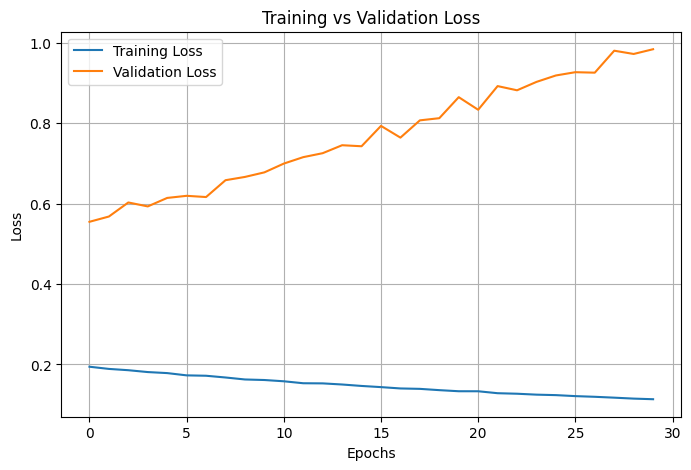

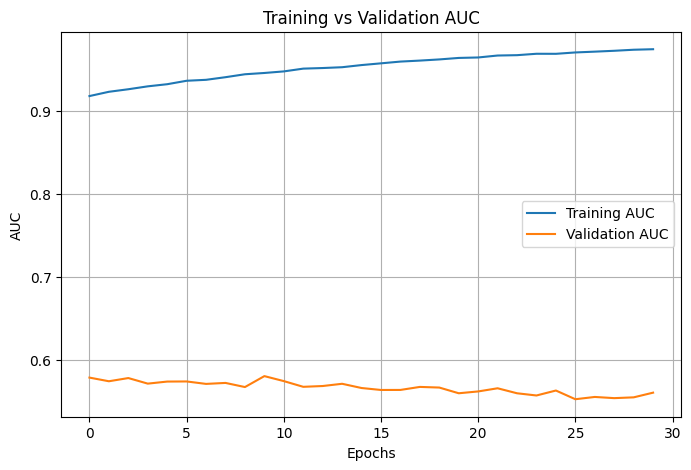

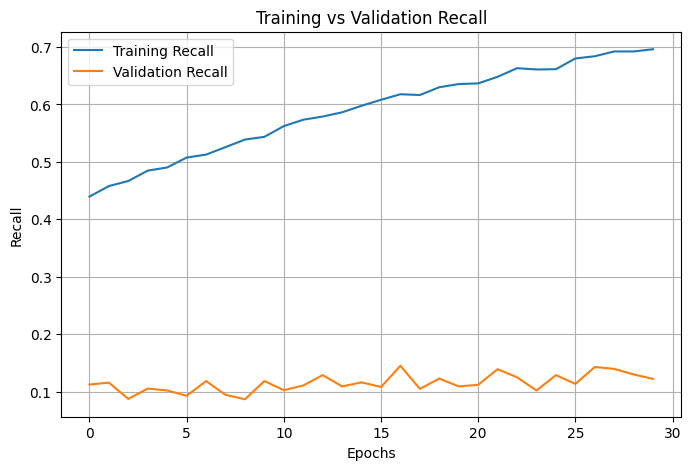

In [122]:
import matplotlib.pyplot as plt

# Plot training and validation loss
plt.figure(figsize=(8, 5))

plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.title('Training vs Validation Loss')
plt.legend()
plt.grid(True)
plt.show()


# Plot training and validation AUC
plt.figure(figsize=(8, 5))

plt.plot(history.history['auc'], label='Training AUC')
plt.plot(history.history['val_auc'], label='Validation AUC')

plt.xlabel('Epochs')
plt.ylabel('AUC')
plt.title('Training vs Validation AUC')
plt.legend()
plt.grid(True)
plt.show()


# Plot training and validation recall
plt.figure(figsize=(8, 5))

plt.plot(history.history['recall'], label='Training Recall')
plt.plot(history.history['val_recall'], label='Validation Recall')

plt.xlabel('Epochs')
plt.ylabel('Recall')
plt.title('Training vs Validation Recall')
plt.legend()
plt.grid(True)
plt.show()

#### Regularization

In [124]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense, Dropout
from tensorflow.keras.regularizers import l2
from tensorflow.keras.callbacks import EarlyStopping

In [125]:
model_regularized = Sequential([
    Input(shape=(X_train_processed.shape[1],)),

    Dense(128, activation='relu', kernel_regularizer=l2(0.001)),
    Dropout(0.3),

    Dense(64, activation='relu', kernel_regularizer=l2(0.001)),
    Dropout(0.3),

    Dense(1, activation='sigmoid')
])

In [126]:
model_regularized.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=[
        'accuracy',
        tf.keras.metrics.Precision(name='precision'),
        tf.keras.metrics.Recall(name='recall'),
        tf.keras.metrics.AUC(name='auc')
    ]
)

In [127]:
early_stopping = EarlyStopping(
    monitor='val_auc',
    mode='max',
    patience=5,
    restore_best_weights=True
)

In [128]:
history_regularized = model_regularized.fit(
    X_fit,
    y_fit,
    validation_data=(X_val, y_val),
    epochs=30,
    batch_size=64,
    callbacks=[early_stopping],
    verbose=1
)

Epoch 1/30
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.8867 - auc: 0.6086 - loss: 0.4113 - precision: 0.3740 - recall: 0.0064 - val_accuracy: 0.8858 - val_auc: 0.6632 - val_loss: 0.3664 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00
Epoch 2/30
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.8871 - auc: 0.6333 - loss: 0.3549 - precision: 0.4516 - recall: 0.0019 - val_accuracy: 0.8858 - val_auc: 0.6633 - val_loss: 0.3469 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00
Epoch 3/30
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.8873 - auc: 0.6387 - loss: 0.3466 - precision: 0.5636 - recall: 0.0043 - val_accuracy: 0.8858 - val_auc: 0.6647 - val_loss: 0.3470 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00
Epoch 4/30
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.8872 - auc: 0.6436 - loss: 0.3439 - precision: 0.5135 - recall: 0.0026 - val_accuracy: 0.8858 - val_auc: 0.6660 - val_loss: 0.3424 - val_precision: 0.4000 - val_recall: 0.0011


- result shows an important improvement, but we have uncovered another problem: the model is barely identifying any patients who will be readmitted within 30 days.

- Validation AUC increased from 0.5607 to 0.6670.

- Validation loss decreased significantly.

- Validation accuracy is now close to the majority-class baseline.

### Examine validation predictions

In [129]:
import numpy as np
from sklearn.metrics import confusion_matrix, classification_report

# Predict probabilities on validation data
y_val_prob = model_regularized.predict(X_val).ravel()

# Convert probabilities into binary predictions
y_val_pred = (y_val_prob >= 0.5).astype(int)

print("Probability Statistics:")
print(pd.Series(y_val_prob).describe())

print("\nPredicted Class Distribution:")
print(pd.Series(y_val_pred).value_counts())

print("\nConfusion Matrix:")
print(confusion_matrix(y_val, y_val_pred))

print("\nClassification Report:")
print(classification_report(y_val, y_val_pred, zero_division=0))

503/503 ━━━━━━━━━━━━━━━━━━━━ 0s 612us/step
Probability Statistics:
count    16090.000000
mean         0.123671
std          0.061285
min          0.012993
25%          0.082870
50%          0.115847
75%          0.148640
max          0.596976
dtype: float64

Predicted Class Distribution:
0    16078
1       12
Name: count, dtype: int64

Confusion Matrix:
[[14246     7]
 [ 1832     5]]

Classification Report:
              precision    recall  f1-score   support

         0.0       0.89      1.00      0.94     14253
         1.0       0.42      0.00      0.01      1837

    accuracy                           0.89     16090
   macro avg       0.65      0.50      0.47     16090
weighted avg       0.83      0.89      0.83     16090



I  have identified the exact problem. The regularized model is learning some separation between the two classes, but its predictions are heavily concentrated below 0.5.

#### Test different thresholds

- Lower threshold → More patients identified as high risk, but potentially more false alarms.

- Higher threshold → Fewer false alarms, but potentially more missed readmissions.

In [130]:
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

thresholds = [0.05, 0.10, 0.15, 0.20, 0.25, 0.30, 0.35, 0.40, 0.50]

results = []

for threshold in thresholds:

    y_pred = (y_val_prob >= threshold).astype(int)

    results.append({
        'Threshold': threshold,
        'Precision': precision_score(y_val, y_pred, zero_division=0),
        'Recall': recall_score(y_val, y_pred, zero_division=0),
        'F1 Score': f1_score(y_val, y_pred, zero_division=0),
        'Predicted Readmissions': sum(y_pred)
    })

threshold_df = pd.DataFrame(results)

print(threshold_df.round(4).to_string(index=False))

 Threshold  Precision  Recall  F1 Score  Predicted Readmissions
      0.05     0.1200  0.9815    0.2138                   15029
      0.10     0.1476  0.8089    0.2497                   10066
      0.15     0.2069  0.4398    0.2814                    3906
      0.20     0.2686  0.2118    0.2368                    1448
      0.25     0.3274  0.1100    0.1646                     617
      0.30     0.3792  0.0675    0.1146                     327
      0.35     0.4072  0.0370    0.0679                     167
      0.40     0.3651  0.0125    0.0242                      63
      0.50     0.4167  0.0027    0.0054                      12


- This experiment confirms that the classification threshold has a major effect on readmission detection

#### Calculate class weights

In [131]:
from sklearn.utils.class_weight import compute_class_weight
import numpy as np

classes = np.array([0, 1])

weights = compute_class_weight(
    class_weight='balanced',
    classes=classes,
    y=y_fit
)

class_weights = dict(zip(classes, weights))

print("Class weights:", class_weights)

Class weights: {np.int64(0): np.float64(0.56358620932774), np.int64(1): np.float64(4.431670131670131)}


## Weighted Model

In [137]:
model_weighted = Sequential([
    Input(shape=(X_train_processed.shape[1],)),

    Dense(128, activation='relu', kernel_regularizer=l2(0.001)),
    Dropout(0.3),

    Dense(64, activation='relu', kernel_regularizer=l2(0.001)),
    Dropout(0.3),

    Dense(1, activation='sigmoid')
])

In [138]:
model_weighted.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=[
        'accuracy',
        tf.keras.metrics.Precision(name='precision'),
        tf.keras.metrics.Recall(name='recall'),
        tf.keras.metrics.AUC(name='auc')
    ]
)

In [139]:
early_stopping_weighted = EarlyStopping(
    monitor='val_auc',
    mode='max',
    patience=5,
    restore_best_weights=True
)


In [145]:
history_weighted = model_weighted.fit(
    X_fit,
    y_fit,
    validation_data=(X_val, y_val),
    epochs=30,
    batch_size=64,
    class_weight=class_weights,
    callbacks=[early_stopping_weighted],
    verbose=1
)

Epoch 1/30
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.6174 - auc: 0.6664 - loss: 0.6580 - precision: 0.1717 - recall: 0.6252 - val_accuracy: 0.5646 - val_auc: 0.6657 - val_loss: 0.6765 - val_precision: 0.1628 - val_recall: 0.6794
Epoch 2/30
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.6223 - auc: 0.6655 - loss: 0.6583 - precision: 0.1722 - recall: 0.6168 - val_accuracy: 0.6260 - val_auc: 0.6681 - val_loss: 0.6332 - val_precision: 0.1760 - val_recall: 0.6179
Epoch 3/30
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.6161 - auc: 0.6654 - loss: 0.6589 - precision: 0.1712 - recall: 0.6252 - val_accuracy: 0.5022 - val_auc: 0.6691 - val_loss: 0.7417 - val_precision: 0.1557 - val_recall: 0.7594
Epoch 4/30
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.6198 - auc: 0.6673 - loss: 0.6572 - precision: 0.1720 - recall: 0.6213 - val_accuracy: 0.6326 - val_auc: 0.6684 - val_loss: 0.6455 - val_precision: 0.1745 - val_recall: 0.5944
Epoch 5/30
1000/1000 ━━━

- Validation recall increased substantially.
- Validation AUC improved slightly, from 0.6670 to 0.6700.
- Precision decreased because the model is identifying more patients as potential readmissions.
- Accuracy decreased because the model is no longer predicting almost everyone as negative.
- This is an important result: class weighting has made the model much more sensitive to readmission cases, but we need to investigate the precision-recall balance.


### Evaluate the weighted model at different thresholds

In [150]:
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

# Predictions using the restored best weights
y_val_prob_weighted = model_weighted.predict(X_val).ravel()

thresholds = [0.05, 0.10, 0.15, 0.20, 0.25, 0.30, 0.35, 0.40, 0.50]

results_weighted = []

for threshold in thresholds:

    y_pred = (y_val_prob_weighted >= threshold).astype(int)

    results_weighted.append({
        'Threshold': threshold,
        'Precision': precision_score(y_val, y_pred, zero_division=0),
        'Recall': recall_score(y_val, y_pred, zero_division=0),
        'F1 Score': f1_score(y_val, y_pred, zero_division=0),
        'Predicted Readmissions': sum(y_pred)
    })

weighted_threshold_df = pd.DataFrame(results_weighted)

print(weighted_threshold_df.round(4).to_string(index=False))

503/503 ━━━━━━━━━━━━━━━━━━━━ 0s 526us/step
 Threshold  Precision  Recall  F1 Score  Predicted Readmissions
      0.05     0.1142  1.0000    0.2049                   16090
      0.10     0.1142  1.0000    0.2049                   16090
      0.15     0.1143  1.0000    0.2051                   16072
      0.20     0.1154  0.9973    0.2068                   15878
      0.25     0.1184  0.9858    0.2115                   15292
      0.30     0.1235  0.9510    0.2186                   14143
      0.35     0.1315  0.8966    0.2294                   12525
      0.40     0.1418  0.8296    0.2422                   10748
      0.50     0.1628  0.6794    0.2627                    7664


- This is an interesting result. Class weighting has significantly changed the model's behaviour. It is now identifying many more potential readmissions, but it is also generating many false positives.
- This means 0.15 is not a suitable threshold for the weighted model.

#### Test higher thresholds

In [151]:
thresholds = [
    0.50, 0.55, 0.60, 0.65,
    0.70, 0.75, 0.80, 0.85, 0.90
]

results_high = []

for threshold in thresholds:

    y_pred = (y_val_prob_weighted >= threshold).astype(int)

    results_high.append({
        'Threshold': threshold,
        'Precision': precision_score(y_val, y_pred, zero_division=0),
        'Recall': recall_score(y_val, y_pred, zero_division=0),
        'F1 Score': f1_score(y_val, y_pred, zero_division=0),
        'Predicted Readmissions': sum(y_pred)
    })

high_threshold_df = pd.DataFrame(results_high)

print(high_threshold_df.round(4).to_string(index=False))

 Threshold  Precision  Recall  F1 Score  Predicted Readmissions
      0.50     0.1628  0.6794    0.2627                    7664
      0.55     0.1832  0.5596    0.2760                    5611
      0.60     0.2184  0.3952    0.2813                    3324
      0.65     0.2524  0.2455    0.2489                    1787
      0.70     0.3016  0.1399    0.1911                     852
      0.75     0.3471  0.0778    0.1272                     412
      0.80     0.3814  0.0403    0.0729                     194
      0.85     0.3837  0.0180    0.0343                      86
      0.90     0.4667  0.0076    0.0150                      30


The weighted model performs slightly better based on F1 and recall, while the regularized model has slightly better precision.

My recommendation: Keep the class-weighted model as our current leading candidate, using 0.55 as its provisional threshold.

### inspect its confusion matrix

In [152]:
from sklearn.metrics import confusion_matrix, classification_report

best_threshold = 0.55

y_val_pred_weighted = (
    y_val_prob_weighted >= best_threshold
).astype(int)

cm = confusion_matrix(y_val, y_val_pred_weighted)

print("Confusion Matrix:")
print(cm)

print("\nClassification Report:")
print(classification_report(
    y_val,
    y_val_pred_weighted,
    zero_division=0
))

Confusion Matrix:
[[9670 4583]
 [ 809 1028]]

Classification Report:
              precision    recall  f1-score   support

         0.0       0.92      0.68      0.78     14253
         1.0       0.18      0.56      0.28      1837

    accuracy                           0.66     16090
   macro avg       0.55      0.62      0.53     16090
weighted avg       0.84      0.66      0.72     16090



### Final test evaluation

In [153]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

# Predict probabilities on untouched test data
y_test_prob = model_weighted.predict(X_test_processed).ravel()

# Apply validation-selected threshold
final_threshold = 0.55

y_test_pred = (
    y_test_prob >= final_threshold
).astype(int)

print("Final Test Results")
print("-------------------")

print("Accuracy:", accuracy_score(y_test, y_test_pred))
print("Precision:", precision_score(y_test, y_test_pred, zero_division=0))
print("Recall:", recall_score(y_test, y_test_pred, zero_division=0))
print("F1 Score:", f1_score(y_test, y_test_pred, zero_division=0))
print("ROC-AUC:", roc_auc_score(y_test, y_test_prob))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_test_pred))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_test_pred,
    zero_division=0
))

628/628 ━━━━━━━━━━━━━━━━━━━━ 0s 626us/step
Final Test Results
-------------------
Accuracy: 0.6705354919053549
Precision: 0.18218026257560113
Recall: 0.5357917570498916
F1 Score: 0.2719066490532805
ROC-AUC: 0.6592278169964002

Confusion Matrix:
[[12226  5544]
 [ 1070  1235]]

Classification Report:
              precision    recall  f1-score   support

         0.0       0.92      0.69      0.79     17770
         1.0       0.18      0.54      0.27      2305

    accuracy                           0.67     20075
   macro avg       0.55      0.61      0.53     20075
weighted avg       0.83      0.67      0.73     20075



Our final test AUC is 0.6592, which indicates modest discrimination between patients who will and will not be readmitted.

The F1 score is 27.19%, slightly below validation's 28.60%. This small difference is encouraging, but overall predictive performance still needs improvement.

##  Error Analysis

In [155]:
# Create an error analysis DataFrame
error_df = X_test.copy()

error_df['Actual'] = y_test.values
error_df['Predicted'] = y_test_pred
error_df['Predicted_Probability'] = y_test_prob

error_df['Prediction_Result'] = np.select(
    [
        (error_df['Actual'] == 1) & (error_df['Predicted'] == 1),
        (error_df['Actual'] == 0) & (error_df['Predicted'] == 0),
        (error_df['Actual'] == 1) & (error_df['Predicted'] == 0),
        (error_df['Actual'] == 0) & (error_df['Predicted'] == 1)
    ],
    [
        'True Positive',
        'True Negative',
        'False Negative',
        'False Positive'
    ],
    default='Unknown'
)

print(error_df['Prediction_Result'].value_counts())

Prediction_Result
True Negative     12226
False Positive     5544
True Positive      1235
False Negative     1070
Name: count, dtype: int64


What do these results tell us?
1. True Negative – 12,226: The model correctly identified patients who were not readmitted within 30 days.
2. False Positive – 5,544: The model predicted readmission, but these patients were not readmitted within 30 days.
3. True Positive – 1,235: The model correctly identified patients who were readmitted within 30 days.
4. False Negative – 1,070: The model failed to identify patients who were actually readmitted within 30 days.

**Important observation:** False positives (5,544) are considerably higher than false negatives (1,070). The model catches approximately 53.58% of actual readmissions, but generates many false alarms.

In [156]:
# Extract false negative records
false_negative_df = error_df[
    error_df['Prediction_Result'] == 'False Negative'
].copy()

print("False Negative Records:", len(false_negative_df))

# Display prediction probability statistics
print("\nPrediction Probability Summary:")
print(false_negative_df['Predicted_Probability'].describe())

# Display sample records
display(false_negative_df.head(10))

False Negative Records: 1070

Prediction Probability Summary:
count    1070.000000
mean        0.425754
std         0.091533
min         0.154742
25%         0.360129
50%         0.436729
75%         0.505803
max         0.549964
Name: Predicted_Probability, dtype: float64


,race,gender,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,number_diagnoses,...,diag_3_group,admission_type_group,admission_source_group,discharge_group,medical_specialty_group,payer_code_group,Actual,Predicted,Predicted_Probability,Prediction_Result
220,Caucasian,Male,8,73,2,19,0,0,0,9,...,Other,Unknown / Unavailable,Emergency Room,Unknown / Unavailable,Family/GeneralPractice,Unknown,1.0,0,0.514682,False Negative
240,Caucasian,Male,6,64,1,11,0,0,0,6,...,Circulatory,Unknown / Unavailable,Physician / Clinic Referral,Home,InternalMedicine,Unknown,1.0,0,0.331293,False Negative
424,AfricanAmerican,Male,3,47,0,2,0,0,0,5,...,Other,Unknown / Unavailable,Emergency Room,Unknown / Unavailable,InternalMedicine,Unknown,1.0,0,0.402515,False Negative
512,Caucasian,Male,6,75,5,20,0,0,0,9,...,Circulatory,Urgent,Physician / Clinic Referral,Home,Unknown,Unknown,1.0,0,0.509968,False Negative
608,Caucasian,Male,5,38,0,20,0,0,0,9,...,Respiratory,Unknown / Unavailable,Physician / Clinic Referral,Unknown / Unavailable,Cardiology,Unknown,1.0,0,0.457438,False Negative
961,Hispanic,Female,2,66,0,3,0,0,0,3,...,Other,Unknown / Unavailable,Emergency Room,Home,Unknown,Unknown,1.0,0,0.277019,False Negative
1023,Caucasian,Female,7,67,0,21,0,0,0,7,...,Genitourinary,Unknown / Unavailable,Emergency Room,Home,Unknown,Unknown,1.0,0,0.548369,False Negative
1182,Caucasian,Female,2,40,1,10,0,0,0,7,...,Other,Emergency,Emergency Room,Home,Surgery-General,Unknown,1.0,0,0.350685,False Negative
1232,Caucasian,Female,11,78,2,28,0,0,0,9,...,Diabetes,Emergency,Physician / Clinic Referral,Home,Family/GeneralPractice,Unknown,1.0,0,0.535931,False Negative
1249,Caucasian,Female,12,39,5,29,0,0,1,8,...,Neoplasms,Elective,Hospital Transfer,Home,Cardiology,Unknown,1.0,0,0.527324,False Negative


In [157]:
# Consider only patients who were actually readmitted
actual_positive_df = error_df[error_df['Actual'] == 1].copy()

# Select numerical features
numerical_features = X_test.select_dtypes(
    include=['int64', 'float64']
).columns.tolist()

# Compare True Positives and False Negatives
comparison = actual_positive_df.groupby(
    'Prediction_Result'
)[numerical_features].agg(['mean', 'median'])

# Display comparison
display(comparison.T)

Prediction_Result          False Negative  True Positive
time_in_hospital   mean          4.229907       5.364372
                   median        4.000000       5.000000
num_lab_procedures mean         42.751402      46.605668
                   median       44.000000      47.000000
num_procedures     mean          1.579439       1.032389
                   median        1.000000       1.000000
num_medications    mean         15.540187      18.218623
                   median       14.000000      17.000000
number_outpatient  mean          0.287850       0.553036
                   median        0.000000       0.000000
number_emergency   mean          0.062617       0.465587
                   median        0.000000       0.000000
number_inpatient   mean          0.209346       2.008907
                   median        0.000000       1.000000
number_diagnoses   mean          7.184112       8.105263
                   median        8.000000       9.000000
age_midpoint       mean         65.542056      67.882591
                   median       65.000000      75.000000

### Key Observations

#### 1. Previous Hospital Utilization
This was the most noticeable difference between False Negatives and True Positives.

- False Negatives had an average of **0.21 previous inpatient visits**.
- True Positives had an average of **2.01 previous inpatient visits**.

This suggests that patients with a history of inpatient admissions were more likely to be correctly identified by the model as being at risk of readmission.

#### 2. Hospital Stay Duration

- False Negatives had an average hospital stay of **4.23 days**.
- True Positives had an average hospital stay of **5.36 days**.

Patients correctly identified as readmitted tended to have longer hospital stays, indicating greater clinical complexity or severity.

#### 3. Medication Usage

- False Negatives received an average of **15.54 medications**.
- True Positives received an average of **18.22 medications**.

Higher medication counts among True Positives suggest that the model more effectively captures patients with more intensive treatment requirements.

#### 4. Number of Diagnoses

- False Negatives had an average of **7.18 diagnoses**.
- True Positives had an average of **8.11 diagnoses**.

A greater number of diagnoses is associated with increased medical complexity, which may make readmission risk easier for the model to detect.

### Overall Interpretation

The model appears to perform better for patients exhibiting stronger indicators of healthcare utilization and clinical complexity, such as prior inpatient visits, longer hospital stays, higher medication counts, and more diagnoses. In contrast, patients with fewer historical admissions and less intensive clinical profiles were more likely to be missed (False Negatives).

These findings are descriptive and highlight patterns associated with prediction outcomes; they should not be interpreted as evidence that these features directly caused the prediction errors.


#### Compare categorical characteristics

In [158]:
categorical_features = [
    'race',
    'gender',
    'diag_1_group',
    'admission_type_group',
    'admission_source_group',
    'discharge_group',
    'medical_specialty_group'
]

for col in categorical_features:

    print(f"\n{'='*60}")
    print(f"Feature: {col}")
    print('='*60)

    comparison = pd.crosstab(
        actual_positive_df['Prediction_Result'],
        actual_positive_df[col],
        normalize='index'
    ) * 100

    display(comparison.round(2))


Feature: race


race,AfricanAmerican,Asian,Caucasian,Hispanic,Other,Unknown
Prediction_Result,,,,,,
False Negative,17.57,0.56,76.17,1.59,1.78,2.34
True Positive,18.38,0.57,78.06,1.05,0.89,1.05



Feature: gender


gender,Female,Male
Prediction_Result,,
False Negative,47.57,52.43
True Positive,54.82,45.18



Feature: diag_1_group


diag_1_group,Circulatory,Diabetes,Digestive,Genitourinary,Injury,Musculoskeletal,Neoplasms,Other,Respiratory,Unknown
Prediction_Result,,,,,,,,,,
False Negative,32.34,8.13,9.53,6.17,5.23,5.70,3.74,17.2,11.96,0.00
True Positive,28.50,9.39,8.74,5.67,9.64,3.24,2.19,18.7,13.77,0.16


... (4 outputs left out)


Feature: discharge_group


discharge_group,Home,Hospice,Hospital / Inpatient Transfer,Left Against Medical Advice,Psychiatric / Federal Facility,Rehabilitation / Long-Term Care,Skilled Nursing / Intermediate Care,Unknown / Unavailable
Prediction_Result,,,,,,,,
False Negative,82.62,0.09,2.15,0.84,0.09,0.84,8.13,5.23
True Positive,49.15,0.57,6.64,0.97,0.89,9.23,29.47,3.08



Feature: medical_specialty_group


medical_specialty_group,Cardiology,Emergency/Trauma,Family/GeneralPractice,Gastroenterology,Hematology/Oncology,InternalMedicine,Nephrology,Neurology,ObstetricsandGynecology,Oncology,...,Psychiatry,Pulmonology,Radiologist,Surgery-Cardiovascular/Thoracic,Surgery-General,Surgery-Neuro,Surgery-Thoracic,Surgery-Vascular,Unknown,Urology
Prediction_Result,,,,,,,,,,,,,,,,,,,,,
False Negative,6.26,6.45,6.26,0.65,0.37,12.90,2.15,0.09,0.56,0.65,...,0.75,1.03,2.06,0.37,3.55,0.47,0.19,0.19,49.44,0.84
True Positive,1.86,7.37,8.02,0.81,0.16,15.79,1.78,0.00,0.08,0.49,...,0.89,0.97,0.49,0.08,2.51,0.32,0.00,0.73,54.25,0.40




### Analyze false positives

In [159]:
false_positive_df = error_df[
    error_df['Prediction_Result'] == 'False Positive'
].copy()

true_negative_df = error_df[
    error_df['Prediction_Result'] == 'True Negative'
].copy()

print("False Positives:", len(false_positive_df))
print("True Negatives:", len(true_negative_df))

False Positives: 5544
True Negatives: 12226


In [160]:
numerical_features = [
    'time_in_hospital',
    'num_lab_procedures',
    'num_procedures',
    'num_medications',
    'number_outpatient',
    'number_emergency',
    'number_inpatient',
    'number_diagnoses',
    'age_midpoint'
]

comparison = pd.DataFrame({
    'False Positive Mean': false_positive_df[numerical_features].mean(),
    'True Negative Mean': true_negative_df[numerical_features].mean(),
    'False Positive Median': false_positive_df[numerical_features].median(),
    'True Negative Median': true_negative_df[numerical_features].median()
})

display(comparison.round(2))

,False Positive Mean,True Negative Mean,False Positive Median,True Negative Median
time_in_hospital,5.37,3.85,5.0,3.0
num_lab_procedures,47.34,40.63,48.0,42.0
num_procedures,1.02,1.49,0.0,1.0
num_medications,17.92,15.02,17.0,14.0
number_outpatient,0.58,0.25,0.0,0.0
number_emergency,0.39,0.06,0.0,0.0
number_inpatient,1.44,0.15,1.0,0.0
number_diagnoses,8.20,7.01,9.0,7.0
age_midpoint,69.87,63.80,75.0,65.0



- false-positive patients have several characteristics associated with higher healthcare utilization, even though they were not readmitted within 30 days.

In [162]:
categorical_features = [
    'race',
    'gender',
    'diag_1_group',
    'admission_type_group',
    'admission_source_group',
    'discharge_group',
    'medical_specialty_group'
]

fp_tn_df = error_df[
    error_df['Prediction_Result'].isin(
        ['False Positive', 'True Negative']
    )
].copy()

for col in categorical_features:
    print(f"\n{'='*60}")
    print(f"Feature: {col}")
    print('='*60)

    comparison = pd.crosstab(
        fp_tn_df['Prediction_Result'],
        fp_tn_df[col],
        normalize='index'
    ) * 100

    display(comparison.round(2))


Feature: race


race,AfricanAmerican,Asian,Caucasian,Hispanic,Other,Unknown
Prediction_Result,,,,,,
False Positive,20.26,0.32,75.31,1.71,1.14,1.26
True Negative,18.62,0.84,74.08,2.14,1.80,2.52



Feature: gender


gender,Female,Male,Unknown/Invalid
Prediction_Result,,,
False Positive,56.85,43.13,0.02
True Negative,51.68,48.32,0.00



Feature: diag_1_group


diag_1_group,Circulatory,Diabetes,Digestive,Genitourinary,Injury,Musculoskeletal,Neoplasms,Other,Respiratory,Unknown
Prediction_Result,,,,,,,,,,
False Positive,30.93,10.23,8.19,5.66,9.43,2.65,2.18,18.07,12.64,0.00
True Negative,29.50,8.16,9.82,4.96,5.66,6.04,3.85,16.89,15.10,0.01


... (4 outputs left out)


Feature: discharge_group


discharge_group,Home,Hospice,Hospital / Inpatient Transfer,Left Against Medical Advice,Other / Special,Psychiatric / Federal Facility,Rehabilitation / Long-Term Care,Skilled Nursing / Intermediate Care,Unknown / Unavailable
Prediction_Result,,,,,,,,,
False Positive,48.83,1.35,6.58,1.05,0.02,0.13,5.99,31.28,4.78
True Negative,86.52,0.45,1.17,0.46,0.03,0.02,0.33,6.30,4.72



Feature: medical_specialty_group


medical_specialty_group,Cardiology,Emergency/Trauma,Endocrinology,Family/GeneralPractice,Gastroenterology,Hematology/Oncology,InternalMedicine,Nephrology,Neurology,ObstetricsandGynecology,...,Psychology,Pulmonology,Radiologist,Surgery-Cardiovascular/Thoracic,Surgery-General,Surgery-Neuro,Surgery-Thoracic,Surgery-Vascular,Unknown,Urology
Prediction_Result,,,,,,,,,,,,,,,,,,,,,
False Positive,2.09,9.2,0.07,7.63,0.51,0.16,15.08,1.68,0.09,0.05,...,0.05,0.94,0.41,0.27,2.31,0.20,0.05,0.43,54.71,0.20
True Negative,6.99,6.4,0.16,7.17,0.63,0.20,14.26,1.28,0.30,0.85,...,0.09,0.97,1.71,0.68,3.30,0.66,0.19,0.43,46.34,0.85


### Combined error analysis: What have I learned?
False Negatives (1,070)

Actual readmissions incorrectly predicted as no readmission.
- More represented among patients discharged home.
- More represented among elective admissions and physician/clinic referrals.
- Generally have lower previous hospital utilization than true positives.

- False Positives (5,544)
Patients predicted as readmitted who were not readmitted within 30 days.
- More represented among emergency admissions and emergency-room admissions.
- More represented among skilled nursing and rehabilitation discharges.
- Have higher previous hospital utilization, longer stays, and more medications than true negatives.

### Important Conclusion

The model appears to identify many patients with stronger indicators of healthcare utilization and clinical complexity, such as frequent inpatient visits, longer hospital stays, and higher medication usage. However, it also generates false-positive predictions for some patients with these characteristics who are not actually readmitted within 30 days.

At the same time, the model misses a subset of true readmission cases, particularly among patients with lower prior healthcare utilization and less intensive clinical profiles.

These findings help explain the patterns behind the model's prediction errors, but they should not be interprete
### Important Conclusions

- The model was more likely to identify patients with stronger indicators of healthcare utilization and clinical complexity, such as:
  - More previous inpatient visits
  - Longer hospital stays
  - Higher medication counts
  - Greater number of diagnoses

- The model also produced false-positive predictions for some patients with these characteristics who were not actually readmitted within 30 days.

- False negatives were more common among patients with:
  - Lower previous healthcare utilization
  - Shorter hospital stays
  - Fewer medications
  - Less complex clinical profiles

- These observations help explain patterns in the model's prediction errors and highlight where the model performs well and where it struggles.

- The observed relationships are descriptive and should **not** be interpreted as evidence that these factors directly caused the prediction errors.

- d as evidence that these factors directly caused the errors.

**Note:** The categorical analyses are based on row-normalized percentages, which describe the composition of the False Positive, True Negative, False Negative, and True Positive groups. They do not directly measure model performance within each category. A more detailed assessment would require category-specific metrics such as precision, recall, or error rates.

## Business Value and Practical Impact

The developed model predicts whether a patient is likely to be readmitted within 30 days after discharge. Such predictions could potentially support healthcare teams by:

- Identifying patients at higher risk of readmission before discharge.
- Supporting discharge planning for patients who may require additional attention.
- Helping prioritize follow-up care, monitoring, or post-discharge interventions.
- Assisting healthcare providers in allocating resources to higher-risk patients.
- Potentially reducing avoidable readmissions when combined with effective clinical interventions.

### Model Performance

| Metric | Result |
|----------|----------|
| Accuracy | 67.05% |
| Precision | 18.22% |
| Recall | 53.58% |
| F1-Score | 27.19% |
| ROC-AUC | 65.92% |

### Confusion Matrix 

| | Predicted No | Predicted Yes |
|---------|-------------|-------------|
| Actual No | 12,226 | 5,544 |
| Actual Yes | 1,070 | 1,235 |

Key observations:

- The model correctly identified **1,235** patients who were readmitted within 30 days.
- It failed to identify **1,070** actual readmissions.
- It incorrectly flagged **5,544** patients as high risk who were not readmitted.
- Only **18.22%** of patients predicted as high risk were actually readmitted.

### Business impact Conclusion

- The model demonstrates the potential of machine learning to support hospital readmission risk assessment.
- It can help identify a portion of patients who may benefit from additional post-discharge attention.
- However, the large number of false-positive predictions means that the model should not be used as the sole basis for clinical decision-making.
- Further model improvement, validation, and testing would be required before considering real-world deployment.
- Although the model could potentially support efforts to reduce readmissions, this project does **not** provide evidence that readmissions or healthcare costs were reduced. Such benefits would need to be evaluated through real-world clinical studies.